In [1]:
import os
import gc
import ast
import random
import warnings
from collections import defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

import implicit

import torch
import torch.nn as nn

import catboost as cb
import shap


warnings.filterwarnings("ignore")
pd.options.mode.chained_assignment = None


DATA_DIR = r"C:\Users\A1ex5\Desktop\CodeFlow\recommender systems\lab_final\KuaiRec 2.0\data"

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

WATCH_RATIO_THR = 0.8

TEST_DAYS = 3
VALID_DAYS = 3

# Для candidate generation важен Recall, поэтому берем не 20, а больше
N_CANDIDATES = 300
FINAL_K = 20

ALS_FACTORS = 96
ALS_REG = 0.05
ALS_ITER = 20
ALS_ALPHA = 20.0

# Доля пользователей, у которых прячем всю историю, чтобы проверить холодный старт
COLD_USER_FRAC = 0.05

# Период полураспада для Popularity (в днях). Подобран на валидации: 1 день лучше 7
POPULARITY_HALF_LIFE = 1

# TwoTower
TT_DIM = 64                  # размер итоговых векторов
TT_HIST_LEN = 50             # сколько последних досмотров пользователя видит user-башня
TT_EPOCHS = 3
TT_BATCH = 4096
TT_LR = 1e-3
TT_TEMPERATURE = 0.05        # температура для softmax по батчу
TT_MIN_ITEM_COUNT = 5        # у видео с меньшим числом досмотров нет своего id-эмбеддинга
TT_HISTORY_DROPOUT = 0.05    # доля примеров, где прячем историю (учим модель работать с новичками)

print("Device:", DEVICE)

Device: cuda


In [2]:
big_df = pd.read_csv(os.path.join(DATA_DIR, "big_matrix.csv"))

big_df_raw = pd.read_csv(os.path.join(DATA_DIR, "big_matrix.csv"))

users_df = pd.read_csv(os.path.join(DATA_DIR, "user_features_raw.csv"))

cats_df = pd.read_csv(os.path.join(DATA_DIR, "item_categories.csv"))

print("big:  ", big_df.shape)
print("users:", users_df.shape)
print("cats: ", cats_df.shape)

display(big_df.head())
display(users_df.head())
display(cats_df.head())

big:   (12530806, 8)
users: (7176, 37)
cats:  (10728, 2)


,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
0,0,3649,13838,10867,2020-07-05 00:08:23.438,20200705,1.593879e+09,1.273397
1,0,9598,13665,10984,2020-07-05 00:13:41.297,20200705,1.593879e+09,1.244082
2,0,5262,851,7908,2020-07-05 00:16:06.687,20200705,1.593879e+09,0.107613
3,0,1963,862,9590,2020-07-05 00:20:26.792,20200705,1.593880e+09,0.089885
4,0,8234,858,11000,2020-07-05 00:43:05.128,20200705,1.593881e+09,0.078000


,user_id,user_active_degree,is_lowactive_period,gender,age_range,is_live_author,is_photo_author,follow_user_num,follow_user_num_range,fans_user_num,...,is_install_douyu,is_install_huya,is_install_yy,platform,os_version,app_download_channel,app_version,app_major_version,app_minor_version,isp
0,0,high_active,0,F,12-17,0,0,5,"(0,10]",0,...,0.0,0.0,0.0,ANDROID_PHONE,22,OPPO,2.6.0.394,2.6,2.6.0,UNKNOWN
1,1,full_active,0,F,24-30,0,0,386,"(250,500]",4,...,0.0,0.0,0.0,ANDROID_PHONE,23,XIAOMI,2.5.1.350,2.5,2.5.1,中国电信
2,2,full_active,0,F,50+,0,0,27,"(10,50]",0,...,0.0,0.0,0.0,ANDROID_PHONE,24,HUAWEI,2.7.30.538,2.6,2.7.30,UNKNOWN
3,3,full_active,0,F,12-17,0,0,16,"(10,50]",0,...,0.0,0.0,0.0,ANDROID_PHONE,22,HUAWEI,2.6.0.394,2.6,2.6.0,中国移动
4,4,full_active,0,F,12-17,0,0,122,"(100,150]",4,...,0.0,0.0,0.0,ANDROID_PHONE,26,"MYAPP,1",2.6.2.448,2.6,2.6.2,中国移动


,video_id,feat
0,0,[8]
1,1,"[27, 9]"
2,2,[9]
3,3,[26]
4,4,[5]


In [3]:
users_df.keys()

Index(['user_id', 'user_active_degree', 'is_lowactive_period', 'gender',
       'age_range', 'is_live_author', 'is_photo_author', 'follow_user_num',
       'follow_user_num_range', 'fans_user_num', 'fans_user_num_range',
       'friend_user_num', 'friend_user_num_range', 'phone_brand',
       'phone_model', 'mod_price', 'fre_country', 'fre_country_region',
       'fre_province', 'fre_city', 'fre_city_level', 'fre_community_type',
       'register_days', 'register_days_range', 'is_install_douyin',
       'is_install_huoshan', 'is_install_xigua', 'is_install_douyu',
       'is_install_huya', 'is_install_yy', 'platform', 'os_version',
       'app_download_channel', 'app_version', 'app_major_version',
       'app_minor_version', 'isp'],
      dtype='object')

In [4]:
print(big_df["watch_ratio"].max())
print(big_df["watch_ratio"].min())

573.4571428571429
0.0


**Data preprocessing**

Я перевожу timestamp в datetime, потому что мне нужно точное время просмотра: для сортировки, для затухания по времени в Popularity и для признаков "сколько дней назад". Готовая колонка date — это просто число вида 20200705, с ним нельзя считать разницу во времени. Timestamp хранится в UTC, а Kuaishou — китайский сервис, поэтому перевожу во время Пекина, чтобы границы дней совпадали с реальными днями пользователей.

In [5]:
def prepare_interactions(df):
    df = df.copy()
    
    assert pd.api.types.is_numeric_dtype(df["date"]), \
       "big_df уже обработан - перезапустите ячейку загрузки данных"
    
    # на крайний случай приводим к числу, чтобы не было проблем с типами
    df["watch_ratio"] = pd.to_numeric(
        df["watch_ratio"],
        errors="coerce"
    )

    # сводится к 5. Нужно для признаков (средний watch_ratio), чтобы выбросы не перекашивали средние.
    df["watch_ratio_clipped"] = df["watch_ratio"].clip(0, 5)

    # implicit target (целевая переменная): видео понравилось, если досмотрено хотя бы на 80%
    df["target"] = (df["watch_ratio"] >= WATCH_RATIO_THR).astype(np.int8)

    # Сохраняем исходный день из данных (число вида 20200705), чтобы потом сверить с timestamp
    df["date_orig"] = pd.to_datetime(
        df["date"].astype(str),
        format="%Y%m%d",
        errors="coerce"
    )

    # timestamp хранится в секундах по UTC. Kuaishou - китайский сервис, поэтому переводим
    # в пекинское время, чтобы границы дней совпадали с реальными днями пользователей,
    # и убираем пометку часового пояса, чтобы дальше работать с обычным datetime
    df["timestamp"] = (
        pd.to_datetime(df["timestamp"], unit="s", utc=True, errors="coerce")
        .dt.tz_convert("Asia/Shanghai")
        .dt.tz_localize(None)
    )

    df = (
        df
        .dropna(subset=["timestamp", "date_orig"])
        .sort_values("timestamp")  # хронологическая сортировка по времени
        .reset_index(drop=True)
    )

    df["date"] = df["timestamp"].dt.normalize()  # оставляем только календарный день

    # Убираем строки с битым timestamp: где день по timestamp не совпадает с днём из данных
    # (в KuaiRec около 0.1% таких строк, расхождение до месяца)
    bad = df["date"] != df["date_orig"]
    print("Rows with broken timestamp removed:", bad.sum())

    df = (
        df[~bad]
        .drop(columns="date_orig")
        .reset_index(drop=True)
    )

    return df


big_df = prepare_interactions(big_df_raw)

print(
    "Date range:",
    big_df["date"].min(),
    "->",
    big_df["date"].max()
)

print("Rows:", len(big_df))
print("Users:", big_df["user_id"].nunique())
print("Items:", big_df["video_id"].nunique())
print("Positive rate:", big_df["target"].mean())

Rows with broken timestamp removed: 15530
Date range: 2020-07-05 00:00:00 -> 2020-09-05 00:00:00
Rows: 12515276
Users: 7176
Items: 10728
Positive rate: 0.453575694215613


In [6]:
big_df

,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio,watch_ratio_clipped,target
0,995,9588,3844,8217,2020-07-05 00:00:02.928,2020-07-05,2020-07-05 00:00:02.927999973,0.467811,0.467811,0
1,2838,103,9790,10300,2020-07-05 00:00:06.174,2020-07-05,2020-07-05 00:00:06.174000025,0.950485,0.950485,1
2,57,1963,1701,9590,2020-07-05 00:00:08.942,2020-07-05,2020-07-05 00:00:08.941999912,0.177372,0.177372,0
3,1319,3509,10416,8934,2020-07-05 00:00:10.39,2020-07-05,2020-07-05 00:00:10.390000105,1.165883,1.165883,1
4,4322,1943,9859,6315,2020-07-05 00:00:11.282,2020-07-05,2020-07-05 00:00:11.282000065,1.561203,1.561203,1
...,...,...,...,...,...,...,...,...,...,...
12515271,1507,5110,5333,3855,2020-09-05 23:59:41.742,2020-09-05,2020-09-05 23:59:41.742000103,1.383398,1.383398,1
12515272,5816,4632,11729,15000,2020-09-05 23:59:42.705,2020-09-05,2020-09-05 23:59:42.704999924,0.781933,0.781933,0
12515273,6288,1368,6282,23963,2020-09-05 23:59:42.852,2020-09-05,2020-09-05 23:59:42.851999998,0.262154,0.262154,0
12515274,2328,9199,20643,9045,2020-09-05 23:59:47.475,2020-09-05,2020-09-05 23:59:47.474999905,2.282255,2.282255,1


In [7]:
def temporal_split(df, valid_days=3, test_days=3):

    dates = np.sort(df["date"].unique())

    assert len(dates) > valid_days + test_days

    test_start = dates[-test_days]

    valid_start = dates[-(valid_days + test_days)]

    train = df[
        df["date"] < valid_start
    ].copy()

    valid = df[
        (df["date"] >= valid_start) &
        (df["date"] < test_start)
    ].copy()

    test = df[
        df["date"] >= test_start
    ].copy()

    return train, valid, test


train_stage1, valid_stage1, test_df = temporal_split(
    big_df,
    VALID_DAYS,
    TEST_DAYS
)

print("TRAIN")
print(train_stage1["date"].min(), "->", train_stage1["date"].max())
print(train_stage1.shape)

print("\nVALID")
print(valid_stage1["date"].min(), "->", valid_stage1["date"].max())
print(valid_stage1.shape)

print("\nTEST")
print(test_df["date"].min(), "->", test_df["date"].max())
print(test_df.shape)

TRAIN
2020-07-05 00:00:00 -> 2020-08-30 00:00:00
(10697721, 10)

VALID
2020-08-31 00:00:00 -> 2020-09-02 00:00:00
(1244951, 10)

TEST
2020-09-03 00:00:00 -> 2020-09-05 00:00:00
(572604, 10)


In [8]:
# Холодные пользователи
# ============================================================
# В KuaiRec у всех пользователей длинная история, настоящих холодных нет.
# Поэтому берём случайные 5% пользователей и прячем всю их историю
# (от генераторов, от признаков и от seen-фильтра). Для системы они как новые.

rng_cold = np.random.default_rng(SEED)

all_user_ids = np.sort(big_df["user_id"].unique())

cold_users = set(
    rng_cold.choice(
        all_user_ids,
        size=int(len(all_user_ids) * COLD_USER_FRAC),
        replace=False
    ).tolist()
)

# train без холодных пользователей - на нём учатся генераторы
train_stage1_warm = train_stage1[
    ~train_stage1["user_id"].isin(cold_users)
]

print("Cold users:", len(cold_users))


def make_ground_truth(df):
    return (
        df[df["target"] == 1]
        .groupby("user_id")["video_id"]
        .apply(set)
        .to_dict()
    )


# набор видео, где target=1, для валидации и теста (грубо говоря видосы, которые понравились юзеру)

valid_gt = make_ground_truth(valid_stage1)


# Все взаимодействия пользователя с видео, которые были в train_stage1 (нужны для фильтрации кандидатов, чтобы не рекомендовать то, что юзер уже видел)
# У холодных пользователей истории "нет"
seen_train = (
    train_stage1_warm
    .groupby("user_id")["video_id"]
    .apply(set)
    .to_dict()
)


print("Users with positive VALID:", len(valid_gt))


Cold users: 358
Users with positive VALID: 6809


In [9]:
# Эта функция парсит категориальнрые признаки из строки в список чисел (категорий). Например, "[1, 6, 3]" -> [1, 6, 3].
def parse_categories(x):

    if pd.isna(x):
        return []

    if isinstance(x, list):
        return x

    try:
        result = ast.literal_eval(str(x))

        if isinstance(result, list):
            return [int(v) for v in result]

    except:
        pass

    return []


cats_df["cat_list"] = cats_df["feat"].apply(parse_categories)

cats_df["primary_cat"] = cats_df["cat_list"].apply(
    lambda x: x[0] if len(x) else -1
)

cats_df["n_categories"] = cats_df["cat_list"].apply(len)


item_cat_map = cats_df.set_index("video_id")[
    "primary_cat"
].to_dict()


**Генераторы**

In [10]:
class BaseGenerator:

    name = "base"

    def fit(self, df):
        raise NotImplementedError

    def score(self, user_id, item_id):
        raise NotImplementedError

    def recommend_many(self, user_ids, seen_map, k): # top_k
        raise NotImplementedError

Эврестический генератор - популярность видео с временным затуханием

Работаем только с взаимодействиями (video_id, target, timestamp)

In [ ]:
class PopularityGenerator(BaseGenerator):

    name = "popularity"

    def __init__(self, half_life_days=7):
        self.half_life_days = half_life_days

    def fit(self, df):

        df = df.copy()

        # Самое свежее взаимодействие, от него берём отчет "старости"
        reference_time = df["timestamp"].max()

        # Возраст каждого взаимодействия относительно reference_time 
        age_days = (
            reference_time - df["timestamp"]
        ).dt.total_seconds() / 86400 # 86400c в 24 часах

        # временное затухание (экспоненциальное) для "временного веса", чем старше видео, тем у него меньше вес. Таким образом мы уменьшаем значимость старых видео в скорах
        # age = 0 → вес 1. age = half_life_days → вес 0.5 (полураспад, как в ядерной физике). age → inf → вес 0.
        df["time_weight"] = np.exp(
            -np.log(2) * age_days / self.half_life_days
        )

        # создаем веса для положитедльных таргетов (1), но каждый положительный таргет ещё зависит от времени, т.е weighted_positive = f(x,t).
        # Если видео старое, то общий вес уменьшается 
        df["weighted_positive"] = (
            df["target"] * df["time_weight"]
        )

        # Агрегируем по каждому видосу по: сумме взвешенных пол.таргетов, сколько раз пользователи смотрели, сырое число таргетов
        stats = (
            df.groupby("video_id")
            .agg(
                positive_score=("weighted_positive", "sum"),
                impressions=("video_id", "size"),
                positive_count=("target", "sum")
            )
            .reset_index()
        )

        # Финальный скор = взвешенная популярность * бонус за массу.
        # np.log1p(x) = log(1+x)
        # Логарифм нужен для сглаживания. Видео могут быть "одноразовыми везунчикам", т.е видео с одним супер-свежим полож.таргетом не вырвется в топ только за счет свжести - нужна и масса и свежесть.
        # Логарифм сглаживает: разница 100 vs 1000 позитивов — не в 10 раз, а в 1.5.
        stats["score"] = (stats["positive_score"] *np.log1p(stats["positive_count"]))


        #score_video = ( Σ_i  target_i × time_weight_i )  ×  log1p( Σ_i target_i )
        #        └──── положительные взаимодействия ────┘  └── количество позитивов ──┘
        
        
        # Сортировка по убыванию скора
        stats = stats.sort_values("score", ascending=False)

        self.ranking = list(
            zip(stats["video_id"], stats["score"])
        )

        self.score_map = dict(self.ranking)

        # дефолтный скор для холодных видео
        self.default_score = 0.0

        return self

    def score(self, user_id, item_id):
        return float(
            self.score_map.get(item_id, self.default_score)
        )

    def recommend_many(self, user_ids, seen_map, k=300):

        result = {}

        for uid in user_ids:

            seen = seen_map.get(uid, set())

            recs = []

            for vid, score in self.ranking:

                if vid not in seen:
                    recs.append((vid, float(score)))

                if len(recs) >= k:
                    break

            result[uid] = recs

        return result

**Почему период полураспада 1 день, а не 7**

Раньше период полураспада был 7 дней, выбранный «на глаз». Я подобрал его экспериментом: Popularity с разными периодами обучался на train и проверялся на первом дне валидации (генераторы рекомендуют на один день вперёд, поэтому и проверяем на одном дне):

| Период полураспада, дней | Recall@20 | NDCG@20 | Recall@300 |
|---|---|---|---|
| **1** | **0.084** | **0.133** | **0.357** |
| 2 | 0.073 | 0.117 | 0.346 |
| 3 | 0.072 | 0.114 | 0.335 |
| 5 | 0.074 | 0.114 | 0.314 |
| 7 | 0.066 | 0.107 | 0.263 |
| 14 | 0.048 | 0.087 | 0.153 |


Важное следствие: с таким коротким периодом Popularity, обученный один раз на train, к тестовым дням полностью устаревает. Поэтому генераторы переобучаются каждый день (см. этап 2).

In [12]:
class ALSGenerator(BaseGenerator):

    name = "als"

    def __init__(
        self,
        factors=96,
        regularization=0.05,
        iterations=20,
        alpha=20.0
    ):

        self.factors = factors
        self.regularization = regularization
        self.iterations = iterations
        self.alpha = alpha

    def fit(self, df):

        # Только положительные взаимодействия 
        pos = df[df["target"] == 1].copy()

        self.user_ids = np.sort(pos["user_id"].unique())
        self.item_ids = np.sort(pos["video_id"].unique())

        self.user_to_idx = {u: i for i, u in enumerate(self.user_ids)}

        self.item_to_idx = {v: i for i, v in enumerate(self.item_ids)}

        self.idx_to_item = self.item_ids

        # номер строки и столбца для каждого досмотра.
        u = pos["user_id"].map(self.user_to_idx).values
        i = pos["video_id"].map(self.item_to_idx).values

        # Уверенность 
        # Пересмотры больше 3 раз не дают дополнительной уверенности, потому что это может быть спам или накрутка. Поэтому ограничиваем максимальную уверенность до 3.
        strength = np.minimum(pos["watch_ratio"].values,3.0)

        # досмотрел на 80% - может, просто не успел пролистать
        # пересмотрел три раза подряд - точно понравилось
        confidence = 1.0 + self.alpha * strength

        # строим разреженную матрицу «пользователи * видео»: хранятся только заполненные клетки
        matrix = sp.coo_matrix(
            (confidence, (u, i)),
            shape=(
                len(self.user_ids),
                len(self.item_ids)
            )
        ).tocsr()

        self.user_item = matrix

        self.model = implicit.als.AlternatingLeastSquares(
            factors=self.factors,
            regularization=self.regularization,
            iterations=self.iterations,
            random_state=SEED
        )

        self.model.fit(matrix)

        self.default_score = 0.0

        return self

    def score(self, user_id, item_id):

        uidx = self.user_to_idx.get(user_id)
        iidx = self.item_to_idx.get(item_id)

        if uidx is None or iidx is None:
            return self.default_score

        return float(
            self.model.user_factors[uidx]
            @
            self.model.item_factors[iidx]
        )

    def recommend_many(self, user_ids, seen_map, k=300):

        result = {}

        # пользователи, которых модель знает; холодным сразу пустой список, у них нет вектора.
        known = [
            u for u in user_ids
            if u in self.user_to_idx
        ]

        # cold users
        for u in user_ids:
            if u not in self.user_to_idx:
                result[u] = []

        if not known:
            return result

        batch_size = 512

        for start in tqdm(
            range(0, len(known), batch_size),
            desc="ALS recommend"
        ):

            batch_users = known[
                start:start + batch_size
            ]

            rows = np.array(
                [self.user_to_idx[u] for u in batch_users],
                dtype=np.int32
            )

            # Просим запас, поскольку ниже фильтруем seen
            N = min(
                len(self.item_ids),
                k + 500
            )

            ids, scores = self.model.recommend(
                rows,
                self.user_item[rows],
                N=N,
                filter_already_liked_items=False
            )

            for row, uid in enumerate(batch_users):

                seen = seen_map.get(uid, set())

                recs = []

                for idx, score in zip(
                    ids[row],
                    scores[row]
                ):

                    vid = self.idx_to_item[idx]

                    if vid in seen:
                        continue

                    recs.append(
                        (vid, float(score))
                    )

                    if len(recs) == k:
                        break

                result[uid] = recs

        return result

**TwoTower**


Три уровня категорий и автор нужны только item-башне TwoTower. В признаки CatBoost они не идут, признаки ранжировщика остались прежними.

In [13]:
# ============================================================
# Готовим признаки для TwoTower

# Три уровня категорий видео. В описаниях есть битые строки, поэтому engine="python".
# -124 в файле означает UNKNOWN, заменяем на -1
# Это описание к видео, отсюда мы можем взять нормальное категориальное представление видео, а не только его id. Башни работают не только с id, но и с признаками. 
caption_df = pd.read_csv(
    os.path.join(DATA_DIR, "kuairec_caption_category.csv"),
    engine="python",
    usecols=[
        "video_id",
        "first_level_category_id",
        "second_level_category_id",
        "third_level_category_id",
    ]
)

caption_df["video_id"] = pd.to_numeric(caption_df["video_id"], errors="coerce")

caption_df = caption_df.dropna(subset=["video_id"]).drop_duplicates("video_id")

caption_df["video_id"] = caption_df["video_id"].astype(int)

# чистим все категории, приводим к int
for new_col, raw_col in [("cat1", "first_level_category_id"),("cat2", "second_level_category_id"),("cat3", "third_level_category_id")]:
    caption_df[new_col] = (pd.to_numeric(caption_df[raw_col], errors="coerce").fillna(-1).astype(int).replace(-124, -1))

# Автор и длительность видео (они не меняются, берём первую запись по каждому видео)
video_static = (pd.read_csv(os.path.join(DATA_DIR, "item_daily_features.csv"),usecols=["video_id", "author_id", "video_duration"]).groupby("video_id").agg(
        author_id=("author_id", "first"),
        video_duration=("video_duration", "max"),
    )
    .reset_index()
)


# Каталог всех видео. Номер 0 зарезервирован под «пусто» (padding в истории пользователя)
# Почему с 1, а не с 0. Номер 0 зарезервирован под «пусто». User-башня получает историю пользователя: 50 последних досмотров. Если пользователь досмотрел всего 3 видео, остальные 47 мест заполняются нулями. Это называется padding (дополнение). Нейросеть знает, что 0 означает «тут ничего нет», и такие места не учитывает.
TT_ITEM_IDS = np.sort(
    np.union1d(cats_df["video_id"].unique(), big_df["video_id"].unique())
)

tt_item_to_idx = {v: i + 1 for i, v in enumerate(TT_ITEM_IDS)}

# Вся информация о видео, которая нужна для TwoTower: категории, автор, длительность. Берём только видео из каталога TT_ITEM_IDS.
tt_meta = (
    pd.DataFrame({"video_id": TT_ITEM_IDS})
    .merge(caption_df[["video_id", "cat1", "cat2", "cat3"]], on="video_id", how="left")
    .merge(video_static, on="video_id", how="left")
    .set_index("video_id")
)


def to_codes(values):
    # категория -> номер с 1 (0 оставляем под padding)
    codes, _ = pd.factorize(pd.Series(values).fillna(-1))
    return np.concatenate([[0], codes + 1]).astype(np.int64)


tt_item_cat1 = to_codes(tt_meta["cat1"].values)
tt_item_cat2 = to_codes(tt_meta["cat2"].values)
tt_item_cat3 = to_codes(tt_meta["cat3"].values)
tt_item_author = to_codes(tt_meta["author_id"].values)

# длительность в миллисекундах сильно скошена, поэтому логарифм, потом стандартизация
log_dur = np.log1p(
    tt_meta["video_duration"].fillna(tt_meta["video_duration"].median()).values / 1000
)
log_dur = (log_dur - log_dur.mean()) / (log_dur.std() + 1e-6)

tt_item_num = np.concatenate([[0.0], log_dur]).astype(np.float32).reshape(-1, 1)


# Пользователи: все из users_df (в том числе холодные - для них будут работать статические признаки)
TT_USER_IDS = np.sort(users_df["user_id"].unique())

tt_user_to_row = {u: i for i, u in enumerate(TT_USER_IDS)}

tt_users = users_df.set_index("user_id").reindex(TT_USER_IDS)

tt_user_age, _ = pd.factorize(tt_users["age_range"].fillna("NA"))
tt_user_activity, _ = pd.factorize(tt_users["user_active_degree"].fillna("NA"))

# Семь числовых признаков пользователя в одну матрицу (7176 * 7).
user_num = np.column_stack([
    np.log1p(tt_users["follow_user_num"].fillna(0)),
    np.log1p(tt_users["fans_user_num"].fillna(0)),
    np.log1p(tt_users["friend_user_num"].fillna(0)),
    np.log1p(tt_users["register_days"].fillna(0)),
    tt_users["is_live_author"].fillna(0),
    tt_users["is_photo_author"].fillna(0),
    tt_users["is_lowactive_period"].fillna(0),
]).astype(np.float32)

tt_user_num = (user_num - user_num.mean(0)) / (user_num.std(0) + 1e-6)


print("Items in TwoTower catalog:", len(TT_ITEM_IDS))
print("Users in TwoTower table:", len(TT_USER_IDS))
print("cat1 / cat2 / cat3 / authors:",
      tt_item_cat1.max(), tt_item_cat2.max(), tt_item_cat3.max(), tt_item_author.max())

Items in TwoTower catalog: 10728
Users in TwoTower table: 7176
cat1 / cat2 / cat3 / authors: 39 138 220 8369


In [14]:
class TwoTowerModel(nn.Module):

    def __init__(
        self,
        item_emb_idx,      # номер видео -> номер его id-эмбеддинга (0 = нет своего эмбеддинга)
        embedding_dim=64,
        hidden_dim=128
    ):

        super().__init__()

        # Таблицы признаков храним внутри модели (buffer): так они сами переезжают на GPU,
        # а признаки берутся по номеру видео / пользователя
        self.register_buffer("item_emb_idx", torch.as_tensor(item_emb_idx))
        self.register_buffer("item_cat1", torch.as_tensor(tt_item_cat1))
        self.register_buffer("item_cat2", torch.as_tensor(tt_item_cat2))
        self.register_buffer("item_cat3", torch.as_tensor(tt_item_cat3))
        self.register_buffer("item_author", torch.as_tensor(tt_item_author))
        self.register_buffer("item_num", torch.as_tensor(tt_item_num))

        self.register_buffer("user_age", torch.as_tensor(tt_user_age, dtype=torch.long))
        self.register_buffer("user_activity", torch.as_tensor(tt_user_activity, dtype=torch.long))
        self.register_buffer("user_num", torch.as_tensor(tt_user_num))

        # id-эмбеддинг видео общий для обеих башен: им описываем и видео-кандидат, и историю пользователя.
        # padding_idx=0: у «пустого» места в истории и у редких видео вектор нулевой
        self.item_id_embedding = nn.Embedding(
            int(item_emb_idx.max()) + 1,
            embedding_dim,
            padding_idx=0
        )

        self.cat1_embedding = nn.Embedding(int(tt_item_cat1.max()) + 1, 16)
        self.cat2_embedding = nn.Embedding(int(tt_item_cat2.max()) + 1, 16)
        self.cat3_embedding = nn.Embedding(int(tt_item_cat3.max()) + 1, 16)
        self.author_embedding = nn.Embedding(int(tt_item_author.max()) + 1, 32)

        self.age_embedding = nn.Embedding(int(tt_user_age.max()) + 1, 8)
        self.activity_embedding = nn.Embedding(int(tt_user_activity.max()) + 1, 8)

        # item-башня: [id, cat1, cat2, cat3, автор, длительность] -> MLP -> вектор
        self.item_mlp = nn.Sequential(
            nn.Linear(embedding_dim + 16 * 3 + 32 + tt_item_num.shape[1], hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, embedding_dim)
        )

        # user-башня: [среднее по истории, возраст, активность, числовые признаки] -> MLP -> вектор
        self.user_mlp = nn.Sequential(
            nn.Linear(embedding_dim + 8 + 8 + tt_user_num.shape[1], hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, embedding_dim)
        )

        for emb in [
            self.item_id_embedding, self.cat1_embedding, self.cat2_embedding,
            self.cat3_embedding, self.author_embedding,
            self.age_embedding, self.activity_embedding
        ]:
            nn.init.normal_(emb.weight, std=0.05)

        with torch.no_grad():
            self.item_id_embedding.weight[0].zero_()

    def item_tower(self, items):
        # items — номера видео в каталоге (с 1)
        x = torch.cat([
            self.item_id_embedding(self.item_emb_idx[items]),
            self.cat1_embedding(self.item_cat1[items]),
            self.cat2_embedding(self.item_cat2[items]),
            self.cat3_embedding(self.item_cat3[items]),
            self.author_embedding(self.item_author[items]),
            self.item_num[items],
        ], dim=-1)

        # L2-нормализация: длина вектора 1, скалярное произведение = косинус
        return nn.functional.normalize(self.item_mlp(x), dim=-1)

    def user_tower(self, history, users):
        # history — [batch, TT_HIST_LEN] номера последних досмотренных видео (0 = пусто)
        # users — номера строк пользователей в таблице признаков

        emb_idx = self.item_emb_idx[history]

        history_vectors = self.item_id_embedding(emb_idx)

        mask = (emb_idx > 0).float().unsqueeze(-1)

        # среднее по реальным (не пустым) видео в истории; у новичка история пустая -> нули
        history_mean = (history_vectors * mask).sum(1) / mask.sum(1).clamp(min=1.0)

        x = torch.cat([
            history_mean,
            self.age_embedding(self.user_age[users]),
            self.activity_embedding(self.user_activity[users]),
            self.user_num[users],
        ], dim=-1)

        return nn.functional.normalize(self.user_mlp(x), dim=-1)

In [15]:
class NeuralGenerator(BaseGenerator):

    name = "two_tower"

    def __init__(
        self,
        embedding_dim=TT_DIM,
        hist_len=TT_HIST_LEN,
        epochs=TT_EPOCHS,
        lr=TT_LR,
        batch_size=TT_BATCH,
        temperature=TT_TEMPERATURE,
        min_item_count=TT_MIN_ITEM_COUNT,
        history_dropout=TT_HISTORY_DROPOUT
    ):

        self.embedding_dim = embedding_dim
        self.hist_len = hist_len
        self.epochs = epochs
        self.lr = lr
        self.batch_size = batch_size
        self.temperature = temperature
        self.min_item_count = min_item_count
        self.history_dropout = history_dropout

    def _positive_sequences(self, df):
        # Все досмотры, отсортированные по пользователю и времени.
        # Для каждой позиции запоминаем, где начинается блок этого пользователя.
        pos = df.loc[
            df["target"] == 1,
            ["user_id", "video_id", "timestamp"]
        ]

        pos = pos[pos["user_id"].isin(tt_user_to_row)]

        pos = pos.sort_values(["user_id", "timestamp"], kind="stable")

        items = pos["video_id"].map(tt_item_to_idx).values.astype(np.int64)
        users = pos["user_id"].map(tt_user_to_row).values.astype(np.int64)

        is_block_start = np.r_[True, users[1:] != users[:-1]]

        block_start = np.maximum.accumulate(
            np.where(is_block_start, np.arange(len(users)), 0)
        )

        return items, users, block_start

    def _history(self, items, block_start, positions):
        # Для каждой позиции — TT_HIST_LEN досмотров СТРОГО ДО неё у того же пользователя.
        # Так модель на обучении не видит будущего.
        offsets = np.arange(self.hist_len, 0, -1)

        idx = positions[:, None] - offsets[None, :]

        valid = idx >= block_start[positions][:, None]

        return np.where(valid, items[np.clip(idx, 0, None)], 0)

    def fit(self, df):

        items, users, block_start = self._positive_sequences(df)

        # Сколько раз каждое видео встречается среди досмотров
        counts = np.bincount(items, minlength=len(TT_ITEM_IDS) + 1)

        # Свой id-эмбеддинг только у видео с достаточным числом досмотров;
        # у редких и новых видео вектор строится только по признакам (категории, автор, длительность)
        frequent = counts >= self.min_item_count
        frequent[0] = False

        item_emb_idx = np.zeros(len(counts), dtype=np.int64)
        item_emb_idx[frequent] = np.arange(1, frequent.sum() + 1)

        # logQ-поправка: популярные видео чаще попадают в батч как негативы,
        # поэтому вычитаем log(частоты видео), чтобы модель не училась просто «топить» популярное
        item_prob = np.maximum(counts, 1) / counts.sum()

        self.log_q = torch.as_tensor(
            np.log(item_prob),
            dtype=torch.float32,
            device=DEVICE
        )

        self.model = TwoTowerModel(
            item_emb_idx,
            embedding_dim=self.embedding_dim
        ).to(DEVICE)

        optimizer = torch.optim.AdamW(
            self.model.parameters(),
            lr=self.lr,
            weight_decay=1e-5
        )

        rng = np.random.default_rng(SEED)

        n = len(items)

        self.model.train()

        for epoch in range(self.epochs):

            losses = []

            permutation = rng.permutation(n)

            for start in tqdm(
                range(0, n, self.batch_size),
                desc=f"TwoTower epoch {epoch+1}"
            ):

                positions = permutation[start:start + self.batch_size]

                history = self._history(items, block_start, positions)

                # иногда прячем всю историю: так модель учится рекомендовать новичкам по профилю
                drop = rng.random(len(positions)) < self.history_dropout
                history[drop] = 0

                history = torch.from_numpy(history).to(DEVICE)
                user_rows = torch.from_numpy(users[positions]).to(DEVICE)
                target_items = torch.from_numpy(items[positions]).to(DEVICE)

                u = self.model.user_tower(history, user_rows)
                v = self.model.item_tower(target_items)

                # Softmax по батчу (InfoNCE): для каждого пользователя правильный ответ — его видео,
                # а видео остальных пользователей батча — негативы.
                # Температура «растягивает» косинусы из [-1, 1], logQ — поправка на популярность.
                logits = (u @ v.T) / self.temperature - self.log_q[target_items][None, :]

                # если одно и то же видео попало в батч несколько раз, это не негатив — маскируем
                same_item = target_items[:, None] == target_items[None, :]
                same_item.fill_diagonal_(False)

                logits = logits.masked_fill(same_item, -1e9)

                labels = torch.arange(len(positions), device=DEVICE)

                loss = nn.functional.cross_entropy(logits, labels)

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                losses.append(loss.item())

            print(
                f"Epoch {epoch+1}: "
                f"loss={np.mean(losses):.5f}"
            )

        self.model.eval()

        # Кэш векторов всех видео каталога (строка 0 — «пусто»)
        with torch.no_grad():

            all_items = torch.arange(1, len(TT_ITEM_IDS) + 1, device=DEVICE)

            item_vectors = self.model.item_tower(all_items).cpu().numpy()

        self.item_vectors = np.vstack([
            np.zeros((1, self.embedding_dim), dtype=np.float32),
            item_vectors
        ])

        self.default_score = 0.0

        # векторы пользователей по их истории на конец обучающих данных
        return self.update_users(df)

    def update_users(self, history_df):
        """
        Пересчитать векторы пользователей по свежей истории без переобучения модели.
        Вызывается каждый день: user-башня видит последние досмотры, поэтому
        вектор пользователя меняется вместе с его вкусами.
        """
        items, users, block_start = self._positive_sequences(history_df)

        present_users, first_index, n_items = np.unique(
            users,
            return_index=True,
            return_counts=True
        )

        # последние TT_HIST_LEN досмотров каждого пользователя
        end = first_index + n_items

        offsets = np.arange(self.hist_len, 0, -1)

        idx = end[:, None] - offsets[None, :]

        valid = idx >= first_index[:, None]

        history = np.zeros((len(TT_USER_IDS), self.hist_len), dtype=np.int64)

        history[present_users] = np.where(valid, items[np.clip(idx, 0, None)], 0)

        user_vectors = []

        with torch.no_grad():

            for start in range(0, len(TT_USER_IDS), 4096):

                rows = np.arange(start, min(start + 4096, len(TT_USER_IDS)))

                user_vectors.append(
                    self.model.user_tower(
                        torch.from_numpy(history[rows]).to(DEVICE),
                        torch.from_numpy(rows).to(DEVICE)
                    ).cpu().numpy()
                )

        self.user_vectors = np.vstack(user_vectors)

        # Рекомендуем только видео, которые уже кто-то смотрел к этому моменту
        # (иначе модель могла бы посоветовать видео, которое ещё не загружено)
        self.active_items = np.zeros(len(TT_ITEM_IDS) + 1, dtype=bool)

        self.active_items[
            history_df["video_id"].map(tt_item_to_idx).dropna().astype(np.int64).unique()
        ] = True

        return self

    def score(self, user_id, item_id):

        row = tt_user_to_row.get(user_id)
        idx = tt_item_to_idx.get(item_id)

        if row is None or idx is None:
            return self.default_score

        return float(self.user_vectors[row] @ self.item_vectors[idx])

    def score_many(self, user_ids, item_ids):

        scores = np.zeros(len(item_ids), dtype=np.float32)

        rows = pd.Series(user_ids).map(tt_user_to_row)
        idx = pd.Series(item_ids).map(tt_item_to_idx)

        valid = np.flatnonzero((rows.notna() & idx.notna()).values)

        scores[valid] = (
            self.user_vectors[rows.iloc[valid].astype(np.int64).values] *
            self.item_vectors[idx.iloc[valid].astype(np.int64).values]
        ).sum(axis=1)

        return scores

    def recommend_many(
        self,
        user_ids,
        seen_map,
        k=300
    ):

        result = {}

        # Вектор есть у любого пользователя из users_df, даже у холодного (по профилю)
        known_users = [u for u in user_ids if u in tt_user_to_row]

        for u in user_ids:
            if u not in tt_user_to_row:
                result[u] = []

        batch_size = 1024

        for start in tqdm(
            range(0, len(known_users), batch_size),
            desc="TwoTower recommend"
        ):

            batch = known_users[start:start + batch_size]

            rows = np.array([tt_user_to_row[u] for u in batch])

            scores = self.user_vectors[rows] @ self.item_vectors.T

            scores[:, ~self.active_items] = -np.inf

            retrieve_k = min(scores.shape[1] - 1, k + 500)

            candidate_idx = np.argpartition(
                -scores,
                retrieve_k - 1,
                axis=1
            )[:, :retrieve_k]

            for row, uid in enumerate(batch):

                idx = candidate_idx[row]
                idx = idx[np.argsort(-scores[row, idx])]

                seen = seen_map.get(uid, set())

                recs = []

                for i in idx:

                    if not np.isfinite(scores[row, i]):
                        break

                    vid = TT_ITEM_IDS[i - 1]

                    if vid in seen:
                        continue

                    recs.append((vid, float(scores[row, i])))

                    if len(recs) >= k:
                        break

                result[uid] = recs

        return result

In [16]:
print("=== Popularity ===")

my_heuristic_model = PopularityGenerator(
    half_life_days=POPULARITY_HALF_LIFE
)

my_heuristic_model.fit(train_stage1_warm)


print("\n=== ALS ===")

my_matrix_factorization = ALSGenerator(
    factors=ALS_FACTORS,
    regularization=ALS_REG,
    iterations=ALS_ITER,
    alpha=ALS_ALPHA
)

my_matrix_factorization.fit(train_stage1_warm)


print("\n=== Two-Tower ===")

my_neural_network = NeuralGenerator()

my_neural_network.fit(train_stage1_warm)

=== Popularity ===

=== ALS ===


  0%|          | 0/20 [00:00<?, ?it/s]


=== Two-Tower ===


TwoTower epoch 1:   0%|          | 0/1134 [00:00<?, ?it/s]

Epoch 1: loss=7.43560


TwoTower epoch 2:   0%|          | 0/1134 [00:00<?, ?it/s]

Epoch 2: loss=7.03215


TwoTower epoch 3:   0%|          | 0/1134 [00:00<?, ?it/s]

Epoch 3: loss=6.95316


In [17]:
def ranking_metrics(
    recommendations,
    ground_truth,
    k=20
):

    recall_values = []
    precision_values = []
    hit_values = []
    ndcg_values = []
    map_values = []

    for user, gt in ground_truth.items():

        if not gt:
            continue

        recs = recommendations.get(
            user,
            []
        )[:k]

        if not recs:
            recall_values.append(0.0)
            precision_values.append(0.0)
            hit_values.append(0.0)
            ndcg_values.append(0.0)
            map_values.append(0.0)
            continue

        relevance = np.array(
            [1 if item in gt else 0 for item in recs]
        )

        hits = relevance.sum()

        recall_values.append(
            hits / len(gt)
        )

        precision_values.append(
            hits / k
        )

        hit_values.append(
            float(hits > 0)
        )

        # NDCG
        discounts = 1 / np.log2(
            np.arange(2, len(recs) + 2)
        )

        dcg = (
            relevance * discounts
        ).sum()

        ideal_len = min(
            len(gt),
            k
        )

        idcg = (
            1 /
            np.log2(
                np.arange(2, ideal_len + 2)
            )
        ).sum()

        ndcg_values.append(
            dcg / idcg
            if idcg > 0
            else 0.0
        )

        # AP@K
        cumulative_hits = np.cumsum(relevance)

        precision_at_i = (
            cumulative_hits /
            np.arange(1, len(recs) + 1)
        )

        ap = (
            precision_at_i * relevance
        ).sum()

        ap /= min(len(gt), k)

        map_values.append(ap)

    return {
        f"Recall@{k}": np.mean(recall_values),
        f"Precision@{k}": np.mean(precision_values),
        f"HitRate@{k}": np.mean(hit_values),
        f"NDCG@{k}": np.mean(ndcg_values),
        f"MAP@{k}": np.mean(map_values)
    }

In [18]:
eval_users = list(valid_gt.keys())

generators = {
    "Popularity": my_heuristic_model,
    "ALS": my_matrix_factorization,
    "TwoTower": my_neural_network
}


generator_recommendations = {}

for name, generator in generators.items():

    print(f"\n{name}")

    raw = generator.recommend_many(
        eval_users,
        seen_train,
        k=N_CANDIDATES
    )

    generator_recommendations[name] = {
        u: [
            item_id
            for item_id, score
            in raw.get(u, [])
        ]
        for u in eval_users
    }

rows = []

for name, recs in generator_recommendations.items():

    m20 = ranking_metrics(
        recs,
        valid_gt,
        k=20
    )

    m100 = ranking_metrics(
        recs,
        valid_gt,
        k=100
    )

    m300 = ranking_metrics(
        recs,
        valid_gt,
        k=300
    )

    rows.append({
        "model": name,

        "Recall@20": m20["Recall@20"],
        "NDCG@20": m20["NDCG@20"],
        "MAP@20": m20["MAP@20"],

        "Recall@100": m100["Recall@100"],

        "Recall@300": m300["Recall@300"]
    })


generator_metrics = pd.DataFrame(rows)

display(
    generator_metrics
    .sort_values(
        "Recall@300",
        ascending=False
    )
)


Popularity

ALS


ALS recommend:   0%|          | 0/13 [00:00<?, ?it/s]


TwoTower


TwoTower recommend:   0%|          | 0/7 [00:00<?, ?it/s]

,model,Recall@20,NDCG@20,MAP@20,Recall@100,Recall@300
2,TwoTower,0.073446,0.190824,0.083440,0.192388,0.344611
0,Popularity,0.056474,0.174016,0.079530,0.152245,0.293020
1,ALS,0.010430,0.026866,0.006759,0.045523,0.095504


Склеили списки рекомендаций от трёх моделей в один пул (с дедупликацией), затем посчитали метрики покрытия (Recall@900, HitRate@900) на этом пуле. Метрики отдельных моделей при этом не смешивались - они просто послужили «источниками» кандидатов.



In [19]:
union_recs = {}

for uid in eval_users:

    combined = []

    seen = set()

    for name in generators:

        for item in generator_recommendations[name].get(uid, []):

            if item not in seen:

                combined.append(item)
                seen.add(item)

    union_recs[uid] = combined


print(
    ranking_metrics(
        union_recs,
        valid_gt,
        k=900
    )
)

{'Recall@900': np.float64(0.41830912987144186), 'Precision@900': np.float64(0.02878020920024151), 'HitRate@900': np.float64(0.9816419444852401), 'NDCG@900': np.float64(0.26822062829260945), 'MAP@900': np.float64(0.061535725765420775)}


Подготовка к этапу 2

In [20]:
# Отберём статические признаки (фичи)
# ============================================================

# item features
item_static_features = cats_df[
    ["video_id", "primary_cat", "n_categories"]
].copy()


# Используем только несколько понятных raw user features.
wanted_user_cols = [
    "user_active_degree",
    "is_lowactive_period",
    "age_range",
    "is_live_author",
    "is_photo_author",
    "follow_user_num",
    "fans_user_num",
    "friend_user_num",
    "fre_city",
    "register_days",
]

available_user_cols = [
    c for c in wanted_user_cols
    if c in users_df.columns
]

user_static_features = users_df[
    ["user_id"] + available_user_cols
].copy()


# Категориальные признаки оставляем строками, CatBoost закодирует их сам (cat_features)
user_cat_cols = []

for c in available_user_cols:

    if not pd.api.types.is_numeric_dtype(user_static_features[c]):

        user_static_features[c] = (
            user_static_features[c]
            .fillna("NA")
            .astype(str)
        )

        user_cat_cols.append(c)

    else:

        user_static_features[c] = pd.to_numeric(
            user_static_features[c],
            errors="coerce"
        )


print("Static user features:")
print(available_user_cols)

# primary_cat — это id категории, а не число, поэтому тоже категориальный
cat_features = ["primary_cat"] + user_cat_cols

print("Categorical features:", cat_features)

display(user_static_features.head())
display(item_static_features.head())

Static user features:
['user_active_degree', 'is_lowactive_period', 'age_range', 'is_live_author', 'is_photo_author', 'follow_user_num', 'fans_user_num', 'friend_user_num', 'fre_city', 'register_days']
Categorical features: ['primary_cat', 'user_active_degree', 'age_range', 'fre_city']


,user_id,user_active_degree,is_lowactive_period,age_range,is_live_author,is_photo_author,follow_user_num,fans_user_num,friend_user_num,fre_city,register_days
0,0,high_active,0,12-17,0,0,5,0,0,汕头,107
1,1,full_active,0,24-30,0,0,386,4,2,江门,327
2,2,full_active,0,50+,0,0,27,0,0,北京,116
3,3,full_active,0,12-17,0,0,16,0,0,聊城,105
4,4,full_active,0,12-17,0,0,122,4,0,宁波,225


,video_id,primary_cat,n_categories
0,0,8,1
1,1,27,2
2,2,9,1
3,3,26,1
4,4,5,1


| Фича | Что означает |
|---|---|
| `user_active_degree` | Уровень общей активности пользователя на платформе. Обычно категориальный признак вроде низкой/средней/высокой активности. |
| `is_lowactive_period` | Флаг того, находится ли пользователь в периоде низкой активности. Обычно бинарный признак `0/1`. |
| `age_range` | Возрастная группа пользователя, а не точный возраст. Например условные диапазоны возраста, закодированные числами. |
| `is_live_author` | Является ли пользователь автором live-контента / стримером. Бинарный признак. |
| `is_photo_author` | Публикует ли пользователь собственный фото/видео-контент. По смыслу это флаг авторства контента. |
| `follow_user_num` | Количество пользователей, на которых подписан данный пользователь. |
| `fans_user_num` | Количество подписчиков / фанатов у пользователя. |
| `friend_user_num` | Количество друзей / взаимных социальных связей. |
| `fre_city` | Город или категориальный идентификатор города, связанный с пользователем. Само точное значение кодировки без документации KuaiRec лучше не интерпретировать как конкретный город. |
| `register_days` | Сколько дней прошло с момента регистрации пользователя на платформе. |

Для заданной даты as_of_date считает по истории (взаимодействия строго до этой даты) агрегированные статистики по 4 разрезам: user, item, user×cat, cat. Возвращает 4 таблички — справочника, которые потом джойнятся к кандидатам

In [ ]:
# Отберём динамические признаки (фичи)
# сколько пользователь смотрел, насколько популярно видео и т. д. Их надо считать на конкретный момент
# ======================================

def build_feature_snapshot(
    history_df,
    as_of_date
):
    """
    Считает исторические признаки только на history_df,
    которая должна содержать взаимодействия строго раньше as_of_date.
    """

    hist = history_df[
        [
            "user_id",
            "video_id",
            "timestamp",
            "target",
            "watch_ratio_clipped"
        ]
    ].copy()

    # Добавляем категорию видео
    hist["primary_cat"] = (
        hist["video_id"]
        .map(item_cat_map)
        .fillna(-1)
        .astype(np.int32)
    )

    # ========================================================
    # USER признаки (фичи)
    # по пользователю: сколько смотрел, сколько уникальных видео, доля досмотров, средний watch_ratio, сколько дней назад был активен;

    user_stats = (
        hist
        .groupby("user_id")
        .agg(
            user_hist_count=("video_id", "size"), # сколько всего просмотров
            user_hist_unique_items=("video_id", "nunique"), # сколько разных видео

            user_hist_positive_count=("target", "sum"), # сколько досмотров
            user_hist_positive_rate=("target", "mean"), # насколько пользователь вообще «досматривающий»

            user_hist_mean_watch_ratio=(   # средняя доля просмотра
                "watch_ratio_clipped ",
                "mean"
            ),

            user_last_timestamp=("timestamp", "max"), # сколько дней назад был активен
        )
        .reset_index()
    )

    as_of_timestamp = pd.Timestamp(as_of_date)

    user_stats["user_days_since_last"] = (
        as_of_timestamp -
        user_stats["user_last_timestamp"]
    ).dt.total_seconds() / 86400

    user_stats.drop(
        columns=["user_last_timestamp"],
        inplace=True
    )

    # ========================================================
    # ITEM признаки (фичи)
    # по видео: сколько раз смотрели, сколько уникальных зрителей, доля досмотров, сколько дней назад смотрели в последний раз;

    item_stats = (
        hist
        .groupby("video_id")
        .agg(
            item_hist_count=("user_id", "size"),
            item_hist_unique_users=("user_id", "nunique"),

            item_hist_positive_count=("target", "sum"),
            item_hist_positive_rate=("target", "mean"),

            item_hist_mean_watch_ratio=(
                "watch_ratio_clipped",
                "mean"
            ),

            item_last_timestamp=("timestamp", "max"),
        )
        .reset_index()
    )

    item_stats["item_days_since_last"] = (
        as_of_timestamp -
        item_stats["item_last_timestamp"]
    ).dt.total_seconds() / 86400

    item_stats.drop(
        columns=["item_last_timestamp"],
        inplace=True
    )

    # ========================================================
    # Взаимодействия юзера * категорию
    # пользователь * категория: сколько раз этот человек смотрел эту категорию и как часто досматривал;
    user_cat_stats = (
        hist[hist["primary_cat"] >= 0]
        .groupby(["user_id", "primary_cat"])
        .agg(
            user_cat_count=("video_id", "size"),

            user_cat_positive_count=("target", "sum"),

            user_cat_positive_rate=("target", "mean"),

            user_cat_mean_watch_ratio=(
                "watch_ratio_clipped",
                "mean"
            ),
        )
        .reset_index()
    )

    # ========================================================
    # CATEGORY признаки (фичи)
    # по категории в целом: насколько она популярна и досматриваема.
    
    cat_stats = (
        hist[hist["primary_cat"] >= 0]
        .groupby("primary_cat")
        .agg(
            cat_hist_count=("video_id", "size"),

            cat_hist_positive_count=("target", "sum"),

            cat_hist_positive_rate=("target", "mean"),

            cat_hist_mean_watch_ratio=(
                "watch_ratio_clipped",
                "mean"
            ),
        )
        .reset_index()
    )

    return {
        "user": user_stats,
        "item": item_stats,
        "user_cat": user_cat_stats,
        "cat": cat_stats,
    }

In [ ]:
def generate_candidate_sources(
    models,
    user_ids,
    seen_map,
    k=300
):
    # Просит каждый генератор выдать по 300 кандидатов для каждого пользователя. Возвращает три отдельных списка: от Popularity, от ALS и от TwoTower.

    source_recs = {}
    
    for name, model in models.items():

        print(f"Candidates: {name}")

        source_recs[name] = model.recommend_many(
            user_ids=user_ids,
            seen_map=seen_map,
            k=k
        )

    return source_recs

# Склеить три списка в одну таблицу пар (пользователь, видео) без дублей и запомнить, кто что предложил.
def candidate_frame_from_sources(
    source_recs,
    user_ids
):

    """
    объединение кандидатов
    Склеивает три списка в одну таблицу пар (пользователь, видео) без дублей. Для каждой пары добавляет:

    source_X - предложил ли это видео генератор X (1/0);
    rank_X - на каком месте у генератора X (9999, если не предлагал);
    candidate_source_count - сколько генераторов предложили это видео.
    """
    rows = {}

    for model_name, user_recs in source_recs.items():

        source_col = f"source_{model_name}"
        rank_col = f"rank_{model_name}"

        for uid in user_ids:

            recs = user_recs.get(uid, [])

            for rank, (vid, score) in enumerate(
                recs,
                start=1
            ):

                key = (uid, vid)

                if key not in rows:

                    rows[key] = {
                        "user_id": uid,
                        "video_id": vid,
                    }

                rows[key][source_col] = 1
                rows[key][rank_col] = rank

    candidates = pd.DataFrame(
        rows.values()
    )

    if len(candidates) == 0:
        return candidates

    # заполняем source flags
    for model_name in source_recs:

        s_col = f"source_{model_name}"
        r_col = f"rank_{model_name}"

        if s_col not in candidates:
            candidates[s_col] = 0

        if r_col not in candidates:
            candidates[r_col] = 9999

        candidates[s_col] = (
            candidates[s_col]
            .fillna(0)
            .astype(np.int8)
        )

        candidates[r_col] = (
            candidates[r_col]
            .fillna(9999)
            .astype(np.int32)
        )

    source_cols = [
        f"source_{name}"
        for name in source_recs
    ]

    candidates["candidate_source_count"] = (
        candidates[source_cols]
        .sum(axis=1)
    )

    return candidates

In [ ]:
# Скор каждого генератора для каждой пары: score_popularity, score_als, score_two_tower. (как фичи для ранжирования)
def add_generator_scores(
    candidates,
    popularity_model,
    als_model,
    neural_model,
    chunk_size=300_000
):
    # Добавляет скор каждого генератора для каждой пары: score_popularity, score_als, score_two_tower.
    
    df = candidates.copy()

    # POPULARITY
    df["score_popularity"] = (
        df["video_id"]
        .map(popularity_model.score_map)
        .fillna(0.0)
        .astype(np.float32)
    )


    # ALS
    df["score_als"] = np.float32(0.0)

    u_idx = df["user_id"].map(
        als_model.user_to_idx
    )

    i_idx = df["video_id"].map(
        als_model.item_to_idx
    )

    valid = (
        u_idx.notna() &
        i_idx.notna()
    )

    valid_positions = np.flatnonzero(
        valid.values
    )

    for start in range(
        0,
        len(valid_positions),
        chunk_size
    ):

        pos = valid_positions[
            start:start + chunk_size
        ]

        us = (
            u_idx.iloc[pos]
            .astype(np.int64)
            .values
        )

        it = (
            i_idx.iloc[pos]
            .astype(np.int64)
            .values
        )

        scores = (
            als_model.model.user_factors[us] *
            als_model.model.item_factors[it]
        ).sum(axis=1)

        df.iloc[
            pos,
            df.columns.get_loc("score_als")
        ] = scores.astype(np.float32)



    # TWO-TOWER
    # Векторы пользователей у TwoTower уже посчитаны по их свежей истории (update_users),
    # поэтому скор = скалярное произведение вектора пользователя и вектора видео
    df["score_two_tower"] = neural_model.score_many(
        df["user_id"].values,
        df["video_id"].values
    )

    return df

In [24]:
def add_history_features(
    candidates,
    snapshot
):
    # Объединяет статические фичи и динамические фичи (историю) для каждой пары (user, video). Возвращает DataFrame с признаками для каждой пары.

    df = candidates.copy()

    # static item
    df = df.merge(
        item_static_features,
        on="video_id",
        how="left"
    )

    # видео без категории: -1, тип всегда int
    df["primary_cat"] = (
        df["primary_cat"]
        .fillna(-1)
        .astype(np.int32)
    )

    # static user
    df = df.merge(
        user_static_features,
        on="user_id",
        how="left"
    )

    # user history
    df = df.merge(
        snapshot["user"],
        on="user_id",
        how="left"
    )

    # item history
    df = df.merge(
        snapshot["item"],
        on="video_id",
        how="left"
    )

    # user-category
    df = df.merge(
        snapshot["user_cat"],
        on=[
            "user_id",
            "primary_cat"
        ],
        how="left"
    )

    # global category
    df = df.merge(
        snapshot["cat"],
        on="primary_cat",
        how="left"
    )

    # ========================================================
    # USER-ITEM RELATION FEATURES

    eps = 1e-6

    # 1.
    df["user_cat_share"] = (
        df["user_cat_count"] /
        (df["user_hist_count"] + eps)
    )

    # 2.
    df["user_cat_positive_share"] = (
        df["user_cat_positive_count"] /
        (df["user_hist_positive_count"] + eps)
    )

    # 3.
    df["user_cat_affinity_lift"] = (
        df["user_cat_positive_rate"] /
        (df["cat_hist_positive_rate"] + eps)
    )

    # 4.
    df["user_item_watch_gap"] = (
        df["user_hist_mean_watch_ratio"] -
        df["item_hist_mean_watch_ratio"]
    ).abs()

    # 5.
    df["user_item_positive_gap"] = (
        df["user_hist_positive_rate"] -
        df["item_hist_positive_rate"]
    ).abs()

    # 6.
    df["user_item_activity_popularity"] = (
        np.log1p(
            df["user_hist_count"].fillna(0)
        )
        *
        np.log1p(
            df["item_hist_count"].fillna(0)
        )
    )

    # Дополнительные полезные interactions

    df["user_item_positive_product"] = (
        df["user_hist_positive_rate"] *
        df["item_hist_positive_rate"]
    )

    df["user_cat_item_quality"] = (
        df["user_cat_positive_rate"] *
        df["item_hist_positive_rate"]
    )

    df["user_cat_watch_item_watch"] = (
        df["user_cat_mean_watch_ratio"] *
        df["item_hist_mean_watch_ratio"]
    )

    # Cold flags
    df["cold_user"] = (
        df["user_hist_count"].isna()
    ).astype(np.int8)

    df["cold_item"] = (
        df["item_hist_count"].isna()
    ).astype(np.int8)

    # NaN -> 0
    numeric_columns = df.select_dtypes(
        include=[np.number]
    ).columns

    df[numeric_columns] = (
        df[numeric_columns]
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
    )

    # NaN -> "NA" для категориальных
    for c in user_cat_cols:
        df[c] = df[c].fillna("NA").astype(str)

    return df

In [ ]:
# Дать каждому кандидату правильный ответ: досмотрел ли пользователь это видео в этот день.
def add_candidate_target(
    candidates,
    target_day
):
    # разметка. Ставит target_ranker = 1, если пользователь в этот день реально досмотрел это видео, иначе 0. Это правильный ответ, на котором учится CatBoost.
    positives = (
        target_day[
            target_day["target"] == 1
        ][["user_id", "video_id"]]
        .drop_duplicates()
        .copy()
    )

    positives["target_ranker"] = 1

    result = candidates.merge(
        positives,
        on=["user_id", "video_id"],
        how="left"
    )

    result["target_ranker"] = (
        result["target_ranker"]
        .fillna(0)
        .astype(np.int8)
    )

    return result

In [26]:
def sample_ranker_training_data(
    df,
    max_negatives_per_user=100,
    seed=42
):
    """
    Позитивов среди кандидатов всего около 1%, а строк миллионы. Поэтому оставляем все позитивы, а негативов (недосмотренных) не больше 100 на пользователя. 
    Обучение идёт быстрее, и позитивы не тонут.
    """

    positives = df[
        df["target_ranker"] == 1
    ].copy()

    negatives = df[
        df["target_ranker"] == 0
    ].copy()

    rng = np.random.default_rng(seed)

    negatives["_random"] = rng.random(
        len(negatives)
    )

    negatives = (
        negatives
        .sort_values(
            ["user_id", "_random"]
        )
        .groupby(
            "user_id",
            group_keys=False
        )
        .head(max_negatives_per_user)
        .drop(columns="_random")
    )

    sampled = pd.concat(
        [
            positives,
            negatives
        ],
        ignore_index=True
    )

    return sampled.sample(
        frac=1,
        random_state=seed
    ).reset_index(drop=True)

**Этап 2** (цикл по дням валидации)

**Скользящее переобучение генераторов.** Раньше генераторы обучались один раз на train и потом без изменений рекомендовали на все дни валидации и теста, то есть к тесту они устаревали на несколько дней. Теперь перед каждым днём генераторы заново обучаются на всей истории **строго до этого дня**: на 01.09 - на данных до 31.08 включительно, на 02.09 - до 01.09 и так далее.

Утечки нет: модель видит прошлые дни, но никогда не видит день, на который рекомендует. Модели переобучают каждый день, потому что тренды меняются. Для коротких видео это особенно важно: у Popularity лучший период полураспада - всего 1 день.

* **Popularity и ALS** обучаются быстро, их каждый день переобучаем полностью.
* **TwoTower** обучается долго, поэтому нейросеть не переобучаем, а пересчитываем векторы пользователей по их свежей истории: user-башня видит последние 50 досмотров, поэтому вектор меняется вместе со вкусами пользователя.

In [27]:
def fit_daily_generators(history, two_tower_model):
    """
    Скользящее переобучение: каждый день обучаем генераторы на всей истории до этого дня (history).
    TwoTower не переобучаем, а только обновляем векторы пользователей по свежей истории.
    """

    print("Daily fit: popularity, als, two_tower (user vectors)")

    daily_popularity = PopularityGenerator(
        half_life_days=POPULARITY_HALF_LIFE
    ).fit(history)

    daily_als = ALSGenerator(
        factors=ALS_FACTORS,
        regularization=ALS_REG,
        iterations=ALS_ITER,
        alpha=ALS_ALPHA
    ).fit(history)

    daily_two_tower = two_tower_model.update_users(history)

    return {
        "popularity": daily_popularity,
        "als": daily_als,
        "two_tower": daily_two_tower,
    }

In [28]:
valid_feature_parts = []

# Уникальные даты валидации по порядку: [31.08, 01.09, 02.09]
valid_dates = sorted(
    valid_stage1["date"].unique()
)

# Цикл по трём дням 
for current_date in valid_dates:

    print("\n" + "=" * 80)
    print("VALID DATE:", current_date)
    print("=" * 80)

    # ИСТОРИЯ: все взаимодействия строго ДО текущего дня,
    # без холодных пользователей (их историю прячем).
    # Из неё считаются признаки, так модель не видит будущее.
    history = big_df[
        (big_df["date"] < current_date) &
        (~big_df["user_id"].isin(cold_users))
    ]

    # ТЕКУЩИЙ ДЕНЬ: что люди реально смотрели в этот день.
    # Отсюда возьмём правильные ответы (таргет).
    current_day = valid_stage1[
        valid_stage1["date"] == current_date
    ]

    # Пользователи, которые были активны в этот день:
    # для них и будем генерировать кандидатов
    user_ids = current_day[
        "user_id"
    ].unique()


    seen_map = (
        history
        .groupby("user_id")["video_id"]   # группируем историю по пользователю
        .apply(set)                       # собираем его видео в множество
        .to_dict()                        # превращаем в словарь
    )

    # СКОЛЬЗЯЩЕЕ ПЕРЕОБУЧЕНИЕ: генераторы дня обучаем на истории строго до этого дня
    daily_models = fit_daily_generators(
        history,
        my_neural_network
    )

    # КАНДИДАТЫ: каждый из трёх генераторов выдаёт по 300 видео каждому пользователю.
    source_recs = generate_candidate_sources(
        daily_models,      # три генератора, обученные на истории до этого дня
        user_ids,          # для кого генерируем
        seen_map,          # что исключить
        k=N_CANDIDATES     # по 300 штук
    )

    # ОБЪЕДИНЕНИЕ: три списка -> одна таблица пар (user_id, video_id) без дублей.
    # Плюс колонки source_X (кто предложил), rank_X (на каком месте),
    # candidate_source_count (сколько генераторов предложили)
    candidates = candidate_frame_from_sources(
        source_recs,
        user_ids
    )

    # Печатаем размер: сколько пар получилось (порядка 4 млн за день)
    print(
        "Raw candidates:",
        candidates.shape
    )

    # ========================================================
    # TARGET
    # Размечаем: target_ranker = 1, если пользователь
    # в этот день досмотрел это видео, иначе 0
    candidates = add_candidate_target(
        candidates,
        current_day
    )

    # Доля позитивов среди кандидатов (~1%)
    print(
        "Candidate positive rate:",
        candidates["target_ranker"].mean()
    )

    # Сколько всего позитивов (сколько кандидатов «угадали»)
    print(
        "Positive candidates:",
        candidates["target_ranker"].sum()
    )

    # ========================================================
    # NEGATIVE SAMPLING
    # Оставляем все позитивы, а негативов не больше 100 на пользователя:
    # таблица становится в ~6 раз меньше, обучение быстрее
    candidates = sample_ranker_training_data(
        candidates,
        max_negatives_per_user=100
    )

    # Размер после сэмплирования (~700 тыс. строк за день)
    print(
        "After sampling:",
        candidates.shape
    )

    # ========================================================
    # GENERATOR SCORES
    # Добавляем три признака: score_popularity, score_als, score_two_tower —
    # насколько каждый генератор «верит» в эту пару
    candidates = add_generator_scores(
        candidates,
        daily_models["popularity"],
        daily_models["als"],
        daily_models["two_tower"]
    )

    # ========================================================
    # HISTORY FEATURES
    # Снимок мира на начало дня: статистики по пользователю, видео,
    # пользователь×категория, категории — только по истории до этого дня
    snapshot = build_feature_snapshot(
        history,
        current_date
    )

    # Подклеиваем к каждой паре статические признаки + статистики из снимка
    # + признаки-связки (любовь к категории, флаги cold_user/cold_item и т.д.)
    candidates = add_history_features(
        candidates,
        snapshot
    )

    # Запоминаем, за какой день эти строки
    # (потом пригодится для группы «пользователь в день» и деления на fit/eval)
    candidates["feature_date"] = (
        pd.Timestamp(current_date)
    )

    # Кладём готовую таблицу дня в общий список
    valid_feature_parts.append(
        candidates
    )

    # Освобождаем память: эти объекты большие, а в следующем дне они не нужны
    del candidates
    del snapshot
    del source_recs
    del daily_models

    # Принудительная сборка мусора: Python сразу возвращает память
    gc.collect()


VALID DATE: 2020-08-31 00:00:00
Daily fit: popularity, als, two_tower (user vectors)


  0%|          | 0/20 [00:00<?, ?it/s]

Candidates: popularity
Candidates: als


ALS recommend:   0%|          | 0/13 [00:00<?, ?it/s]

Candidates: two_tower


TwoTower recommend:   0%|          | 0/7 [00:00<?, ?it/s]

... (9 outputs left out)

ALS recommend:   0%|          | 0/13 [00:00<?, ?it/s]

Candidates: two_tower


TwoTower recommend:   0%|          | 0/7 [00:00<?, ?it/s]

Raw candidates: (4225307, 9)
Candidate positive rate: 0.015055710744805053
Positive candidates: 63615
After sampling: (723515, 10)


In [ ]:
# Обучающие признаки для CatBoost
train_df_with_features = pd.concat(
    valid_feature_parts,
    ignore_index=True
)

del valid_feature_parts
gc.collect()

print(
    "Ranker training dataset:",
    train_df_with_features.shape
)

print(
    "Positive rate:",
    train_df_with_features[
        "target_ranker"
    ].mean()
)

display(
    train_df_with_features.head()
)

Ranker training dataset: (2204351, 57)
Positive rate: 0.09773897169733858


,user_id,video_id,source_popularity,rank_popularity,source_als,rank_als,source_two_tower,rank_two_tower,candidate_source_count,target_ranker,...,user_cat_affinity_lift,user_item_watch_gap,user_item_positive_gap,user_item_activity_popularity,user_item_positive_product,user_cat_item_quality,user_cat_watch_item_watch,cold_user,cold_item,feature_date
0,5148,8206,0,9999,1,264,0,9999,1,0,...,1.199816,0.813120,0.336565,40.120282,0.501089,0.543931,1.953355,0,0,2020-08-31
1,1605,6093,0,9999,0,9999,1,264,1,0,...,0.628223,0.014193,0.062229,56.351023,0.106501,0.081051,0.471735,0,0,2020-08-31
2,2366,9055,1,161,0,9999,0,9999,1,0,...,1.157206,0.460178,0.179969,42.176879,0.389863,0.448080,1.226786,0,0,2020-08-31
3,3345,6202,0,9999,1,34,0,9999,1,0,...,1.092431,0.030367,0.157242,57.382915,0.199340,0.219898,0.843092,0,0,2020-08-31
4,217,4429,1,170,0,9999,1,123,2,1,...,0.966207,0.339614,0.205592,60.213957,0.321362,0.352379,1.049290,0,0,2020-08-31


In [57]:
train_df_with_features.keys()

Index(['user_id', 'video_id', 'source_popularity', 'rank_popularity',
       'source_als', 'rank_als', 'source_two_tower', 'rank_two_tower',
       'candidate_source_count', 'target_ranker', 'score_popularity',
       'score_als', 'score_two_tower', 'primary_cat', 'n_categories',
       'user_active_degree', 'is_lowactive_period', 'age_range',
       'is_live_author', 'is_photo_author', 'follow_user_num', 'fans_user_num',
       'friend_user_num', 'fre_city', 'register_days', 'user_hist_count',
       'user_hist_unique_items', 'user_hist_positive_count',
       'user_hist_positive_rate', 'user_hist_mean_watch_ratio',
       'user_days_since_last', 'item_hist_count', 'item_hist_unique_users',
       'item_hist_positive_count', 'item_hist_positive_rate',
       'item_hist_mean_watch_ratio', 'item_days_since_last', 'user_cat_count',
       'user_cat_positive_count', 'user_cat_positive_rate',
       'user_cat_mean_watch_ratio', 'cat_hist_count',
       'cat_hist_positive_count', 'cat_hist_

Из таблицы убираем служебные колонки: id, таргет, дату, группу. Остальные числовые и категориальные колонки - это признаки, на которых учится CatBoost. Id убираем, чтобы модель не запоминала конкретных пользователей и видео, а таргет - потому что это ответ.

In [30]:
NON_FEATURE_COLUMNS = {
    "user_id",
    "video_id",
    "target_ranker",
    "feature_date",
    "group_id",
}

FEATURE_COLUMNS = [
    c
    for c in train_df_with_features.columns
    if c not in NON_FEATURE_COLUMNS
    and (
        pd.api.types.is_numeric_dtype(train_df_with_features[c])
        or c in cat_features
    )
]

print(
    "Number of features:",
    len(FEATURE_COLUMNS)
)

for i, feature in enumerate(
    FEATURE_COLUMNS,
    start=1
):
    print(
        f"{i:2d}. {feature}"
    )

Number of features: 53
 1. source_popularity
 2. rank_popularity
 3. source_als
 4. rank_als
 5. source_two_tower
 6. rank_two_tower
 7. candidate_source_count
 8. score_popularity
 9. score_als
10. score_two_tower
11. primary_cat
12. n_categories
13. user_active_degree
14. is_lowactive_period
15. age_range
16. is_live_author
17. is_photo_author
18. follow_user_num
19. fans_user_num
20. friend_user_num
21. fre_city
22. register_days
23. user_hist_count
24. user_hist_unique_items
25. user_hist_positive_count
26. user_hist_positive_rate
27. user_hist_mean_watch_ratio
28. user_days_since_last
29. item_hist_count
30. item_hist_unique_users
31. item_hist_positive_count
32. item_hist_positive_rate
33. item_hist_mean_watch_ratio
34. item_days_since_last
35. user_cat_count
36. user_cat_positive_count
37. user_cat_positive_rate
38. user_cat_mean_watch_ratio
39. cat_hist_count
40. cat_hist_positive_count
41. cat_hist_positive_rate
42. cat_hist_mean_watch_ratio
43. user_cat_share
44. user_cat_pos

Этап 3. CatBoost

In [31]:
def prepare_ranker_data(df):
    """
    group_id = пользователь в конкретный день (один "запрос" к системе).
    Ранкер сравнивает кандидатов только внутри одной группы.
    """

    df = df.copy()

    df["group_id"] = (
        df["feature_date"].dt.strftime("%Y%m%d").astype(np.int64) * 100_000
        + df["user_id"]
    )

    # группы без позитивов не нужны: в них нечего упорядочивать
    has_positive = (
        df.groupby("group_id")["target_ranker"]
        .transform("max") == 1
    )

    df = df[has_positive]

    # CatBoost требует, чтобы объекты одной группы шли подряд
    df = df.sort_values("group_id").reset_index(drop=True)

    for c in cat_features:
        df[c] = df[c].astype(str)

    return df


train_df_with_features = prepare_ranker_data(
    train_df_with_features
)

# Последний день валидации откладываем для early stopping
last_valid_date = train_df_with_features["feature_date"].max()

fit_part = train_df_with_features[
    train_df_with_features["feature_date"] < last_valid_date
]

eval_part = train_df_with_features[
    train_df_with_features["feature_date"] == last_valid_date
]

X_train = fit_part[FEATURE_COLUMNS]
y_train = fit_part["target_ranker"]

X_eval = eval_part[FEATURE_COLUMNS]
y_eval = eval_part["target_ranker"]

print(
    X_train.shape,
    y_train.mean()
)

print(
    X_eval.shape,
    y_eval.mean()
)

(1398436, 53) 0.10857558014810832
(655015, 53) 0.0971199132844286


In [32]:
ranker_model = cb.CatBoostRanker(
    iterations=2000,
    depth=8,
    learning_rate=0.05,

    loss_function="YetiRank",

    eval_metric="NDCG:top=20",

    l2_leaf_reg=5,

    # early stopping: если 100 итераций NDCG на отложенном дне не растёт — стоп
    od_type="Iter",
    od_wait=100,
    use_best_model=True,

    random_seed=SEED,

    verbose=100,

    allow_writing_files=False,

    thread_count=-1
)

In [33]:
train_pool = cb.Pool(
    X_train,
    y_train,
    group_id=fit_part["group_id"],
    cat_features=cat_features
)

eval_pool = cb.Pool(
    X_eval,
    y_eval,
    group_id=eval_part["group_id"],
    cat_features=cat_features
)

ranker_model.fit(
    train_pool,
    eval_set=eval_pool
)

print("Best iteration:", ranker_model.get_best_iteration())

Groupwise loss function. OneHotMaxSize set to 10
0:	test: 0.3534258	best: 0.3534258 (0)	total: 1.07s	remaining: 35m 30s
100:	test: 0.5693414	best: 0.5694902 (99)	total: 1m 38s	remaining: 30m 51s
200:	test: 0.5788387	best: 0.5788387 (200)	total: 3m 14s	remaining: 29m 2s
300:	test: 0.5847375	best: 0.5848382 (297)	total: 4m 51s	remaining: 27m 25s
400:	test: 0.5865913	best: 0.5866157 (389)	total: 6m 25s	remaining: 25m 38s
500:	test: 0.5875918	best: 0.5879795 (486)	total: 7m 59s	remaining: 23m 54s
600:	test: 0.5891735	best: 0.5892690 (584)	total: 9m 37s	remaining: 22m 24s
700:	test: 0.5897560	best: 0.5898231 (696)	total: 11m 14s	remaining: 20m 49s
800:	test: 0.5901166	best: 0.5902121 (792)	total: 12m 48s	remaining: 19m 10s
900:	test: 0.5901937	best: 0.5903927 (886)	total: 14m 20s	remaining: 17m 29s
1000:	test: 0.5905031	best: 0.5907823 (959)	total: 15m 50s	remaining: 15m 48s
1100:	test: 0.5911852	best: 0.5912136 (1097)	total: 17m 18s	remaining: 14m 7s
1200:	test: 0.5918690	best: 0.5918728 (

Используем CatBoostRanker с лоссом YetiRank: он учится ставить досмотренные видео выше недосмотренных внутри выдачи одного пользователя за день, это и есть group_id. Учимся на 31.08–01.09, а 02.09 отложен для early stopping по NDCG@20. Обучение останавливается, когда 100 итераций подряд NDCG на отложенном дне не растёт, и модель оставляет лучшую итерацию.

In [34]:
feature_importance_df = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "importance":
        ranker_model.get_feature_importance(
            type="PredictionValuesChange"
        )
})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "importance",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    feature_importance_df.head(30)
)

,feature,importance
0,item_days_since_last,31.894669
1,score_als,10.669303
2,score_popularity,8.950966
3,score_two_tower,7.456336
4,item_hist_unique_users,5.943866
5,item_hist_positive_rate,3.769658
6,item_hist_positive_count,3.554341
7,item_hist_mean_watch_ratio,2.937913
8,user_item_activity_popularity,2.634406
9,item_hist_count,2.524831


1) item_days_since_last - сколько дней назад это видео кто-то смотрел в последний раз.
2) score_als  - скор ALS для пары.
3) score_popularity  - скор Popularity.
4) score_two_tower  - скор TwoTower.
5) item_hist_unique_users  - сколько разных людей смотрели это видео за всю историю.

Самый важный признак - item_days_since_last, то есть свежесть видео: для коротких видео тренды решают. Дальше идут скоры генераторов Popularity и ALS, значит CatBoost активно использует мнение генераторов. Потом статистики популярности видео и активности пользователя. В целом свойства видео важнее свойств пользователя, это объясняет, почему простой Popularity так силён

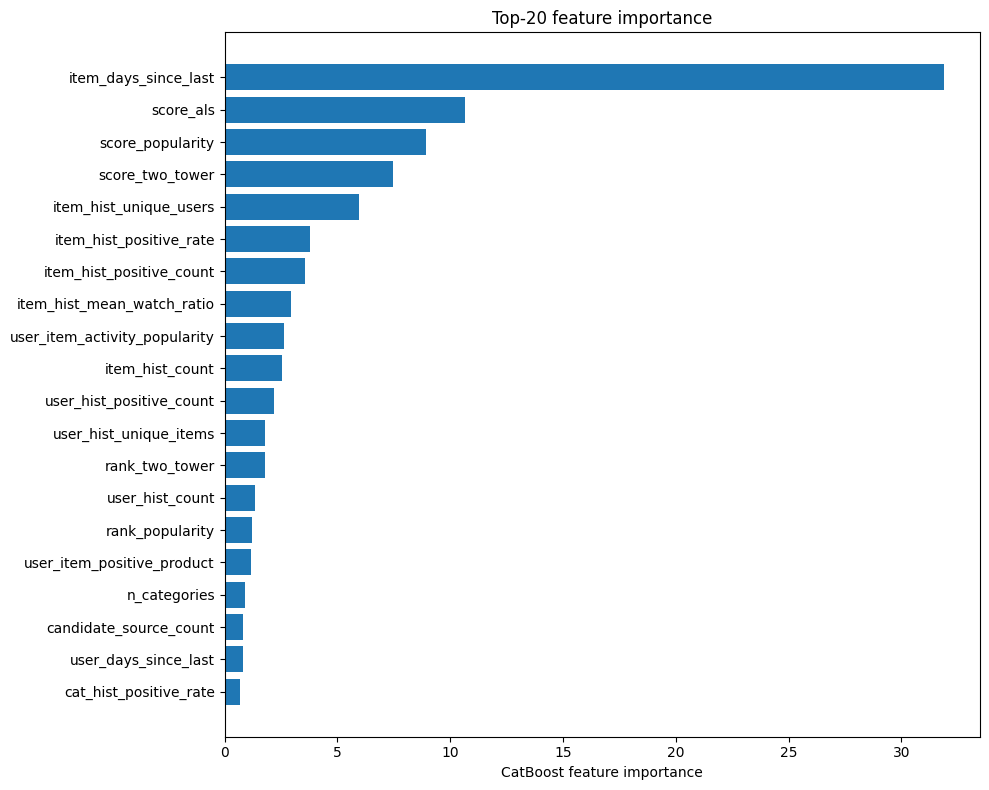

In [35]:
top_imp = feature_importance_df.head(20)

plt.figure(figsize=(10, 8))

plt.barh(
    top_imp["feature"][::-1],
    top_imp["importance"][::-1]
)

plt.xlabel("CatBoost feature importance")
plt.title("Top-20 feature importance")

plt.tight_layout()
plt.show()

SHAP

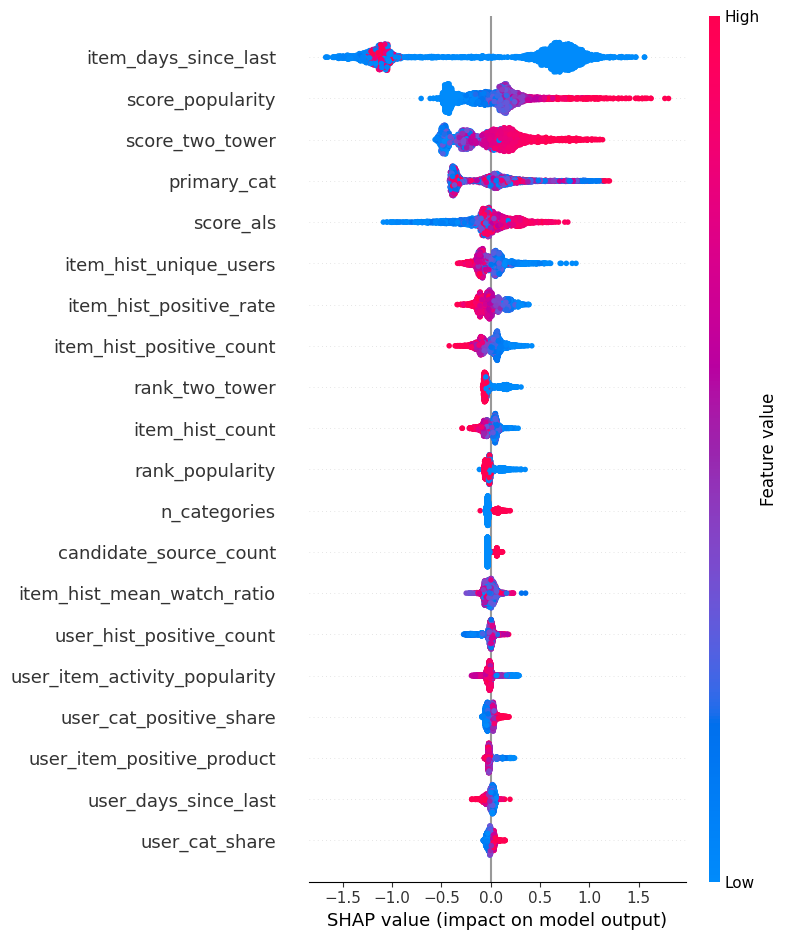

In [36]:
SHAP_SAMPLE_SIZE = min(
    3000,
    len(X_train)
)

X_shap = X_train.sample(
    SHAP_SAMPLE_SIZE,
    random_state=SEED
)

# SHAP считает сам CatBoost (TreeSHAP), он умеет работать с категориальными признаками.
# Последний столбец — базовое значение, его убираем.
shap_values = ranker_model.get_feature_importance(
    data=cb.Pool(X_shap, cat_features=cat_features),
    type="ShapValues"
)[:, :-1]

# для раскраски точек категориальные признаки заменяем кодами
X_shap_plot = X_shap.copy()

for c in cat_features:
    X_shap_plot[c] = pd.factorize(X_shap_plot[c])[0]

shap.summary_plot(
    shap_values,
    X_shap_plot,
    max_display=20
)

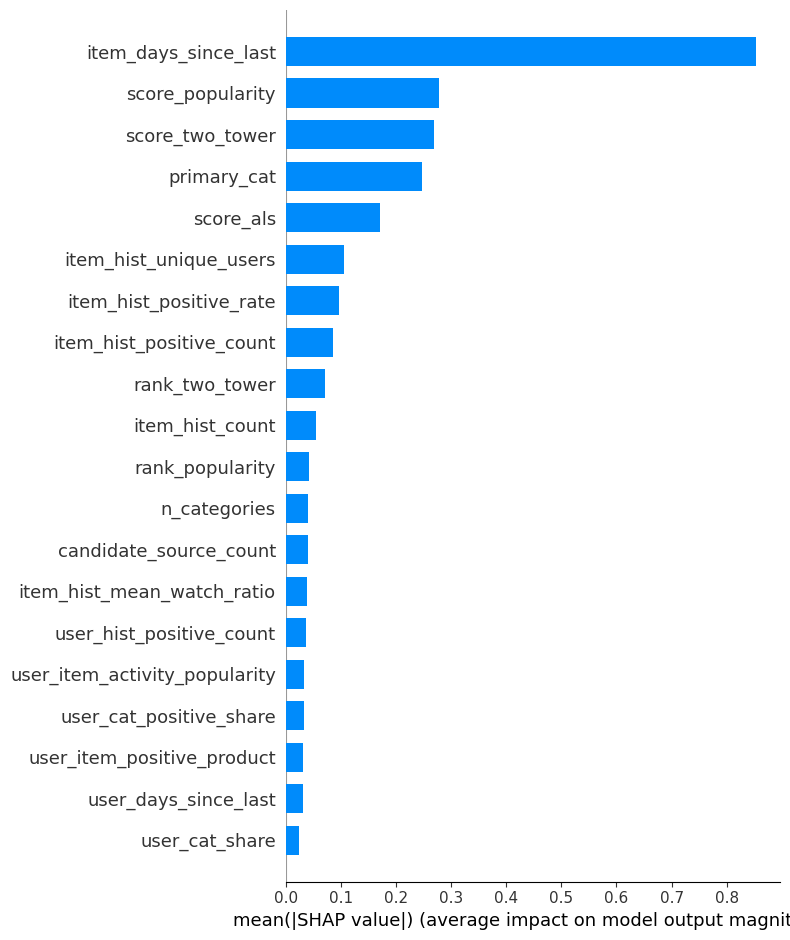

In [37]:
shap.summary_plot(
    shap_values,
    X_shap_plot,
    plot_type="bar",
    max_display=20
)

Честная оценка на TEST

На тесте всё устроено так же, как на валидации: перед каждым тестовым днём Popularity и ALS переобучаются на истории до этого дня, а у TwoTower пересчитываются векторы пользователей. Саму нейросеть TwoTower перед тестом один раз переобучаем на всём, что было до теста (train + валидация). Ранжировщик CatBoost для теста не переобучается: он обучен только на валидации и тестовых дней не видел.

Здесь есть проблема RAM: нельзя создавать одновременно условные 10 миллионов строк test-кандидатов.

Поэтому делаем день → батчи пользователей → score → Top-20 → удалили dataframe.

In [38]:
def make_daily_ground_truth(df):

    positives = df[
        df["target"] == 1
    ]

    result = {}

    for (date, uid), group in positives.groupby(
        ["date", "user_id"]
    ):

        result[
            (pd.Timestamp(date), uid)
        ] = set(
            group["video_id"]
        )

    return result


test_daily_gt = make_daily_ground_truth(
    test_df
)

print(
    "Evaluation groups:",
    len(test_daily_gt)
)

Evaluation groups: 18985


In [39]:
def evaluate_ranker_on_period(
    period_df,
    full_interactions,
    model,
    feature_columns,
    two_tower_model,
    k_candidates=300,
    final_k=20,
    user_batch_size=500
):

    recommendations = {}

    # топ-K каждого генератора в тех же условиях — для честного сравнения
    generator_recommendations = {
        name: {}
        for name in ["popularity", "als", "two_tower"]
    }

    # размеченные кандидаты — для переобучения финального ранкера
    train_parts = []

    dates = sorted(
        period_df["date"].unique()
    )

    for current_date in dates:

        print("\n" + "=" * 80)
        print("TEST DATE:", current_date)
        print("=" * 80)

        current_day = period_df[
            period_df["date"] == current_date
        ]

        history = full_interactions[
            (full_interactions["date"] < current_date) &
            (~full_interactions["user_id"].isin(cold_users))
        ]

        users = current_day[
            "user_id"
        ].unique()

        seen_map = (
            history
            .groupby("user_id")["video_id"]
            .apply(set)
            .to_dict()
        )

        # Snapshot один раз на день
        snapshot = build_feature_snapshot(
            history,
            current_date
        )

        # Скользящее переобучение: генераторы дня обучаем на истории строго до этого дня
        generator_models = fit_daily_generators(
            history,
            two_tower_model
        )

        # Кандидаты один раз на день
        source_recs = generate_candidate_sources(
            generator_models,
            users,
            seen_map,
            k=k_candidates
        )

        for name, user_recs in source_recs.items():
            for uid in users:
                generator_recommendations[name][
                    (pd.Timestamp(current_date), uid)
                ] = [
                    vid for vid, score in user_recs.get(uid, [])
                ][:final_k]

        for start in tqdm(
            range(
                0,
                len(users),
                user_batch_size
            ),
            desc="Ranker batches"
        ):

            batch_users = users[
                start:start + user_batch_size
            ]

            candidates = candidate_frame_from_sources(
                source_recs,
                batch_users
            )

            if candidates.empty:
                continue

            candidates = add_generator_scores(
                candidates,
                generator_models["popularity"],
                generator_models["als"],
                generator_models["two_tower"]
            )

            candidates = add_history_features(
                candidates,
                snapshot
            )

            X = candidates[feature_columns].copy()

            for c in cat_features:
                X[c] = X[c].astype(str)

            # у ранкера predict даёт скор релевантности, важен только порядок
            candidates["ranker_score"] = model.predict(X)

            # Top-K отдельно каждому user
            top = (
                candidates
                .sort_values(
                    [
                        "user_id",
                        "ranker_score"
                    ],
                    ascending=[
                        True,
                        False
                    ]
                )
                .groupby(
                    "user_id",
                    group_keys=False
                )
                .head(final_k)
            )

            for uid, group in top.groupby(
                "user_id"
            ):

                recommendations[
                    (
                        pd.Timestamp(current_date),
                        uid
                    )
                ] = group[
                    "video_id"
                ].tolist()

            # размечаем и сэмплируем кандидатов для финального ранкера
            labeled = add_candidate_target(
                candidates.drop(columns="ranker_score"),
                current_day
            )

            labeled = sample_ranker_training_data(
                labeled,
                max_negatives_per_user=100
            )

            labeled["feature_date"] = pd.Timestamp(current_date)

            train_parts.append(labeled)

            del candidates
            del top
            del labeled

        del snapshot
        del source_recs
        del generator_models

        gc.collect()

    return recommendations, generator_recommendations, train_parts

In [40]:
# TwoTower для теста переобучаем на всём, что было до теста (train + валидация).
# Popularity и ALS переобучаются каждый день внутри evaluate_ranker_on_period
pre_test_history = big_df[
    (big_df["date"] < test_df["date"].min()) &
    (~big_df["user_id"].isin(cold_users))
]

test_two_tower = NeuralGenerator()

test_two_tower.fit(pre_test_history)


(
    test_ranker_recommendations,
    test_generator_recommendations,
    test_train_parts
) = evaluate_ranker_on_period(
    period_df=test_df,

    full_interactions=big_df,

    model=ranker_model,

    feature_columns=FEATURE_COLUMNS,

    two_tower_model=test_two_tower,

    k_candidates=N_CANDIDATES,

    final_k=FINAL_K,

    user_batch_size=500
)

TwoTower epoch 1:   0%|          | 0/1258 [00:00<?, ?it/s]

Epoch 1: loss=7.33354


TwoTower epoch 2:   0%|          | 0/1258 [00:00<?, ?it/s]

Epoch 2: loss=6.93393


TwoTower epoch 3:   0%|          | 0/1258 [00:00<?, ?it/s]

Epoch 3: loss=6.85526

TEST DATE: 2020-09-03 00:00:00
Daily fit: popularity, als, two_tower (user vectors)


... (16 outputs left out)

ALS recommend:   0%|          | 0/12 [00:00<?, ?it/s]

Candidates: two_tower


TwoTower recommend:   0%|          | 0/7 [00:00<?, ?it/s]

Ranker batches:   0%|          | 0/13 [00:00<?, ?it/s]

In [41]:
# Все модели на одних и тех же тестовых днях, пользователях и ground truth
test_models = {
    "Popularity": test_generator_recommendations["popularity"],
    "ALS": test_generator_recommendations["als"],
    "TwoTower": test_generator_recommendations["two_tower"],
    "CatBoostRanker": test_ranker_recommendations,
}

rows = []

for name, recs in test_models.items():

    m = ranking_metrics(
        recommendations=recs,
        ground_truth=test_daily_gt,
        k=FINAL_K
    )

    rows.append({"model": name, **m})

final_test_metrics = pd.DataFrame(rows)

print("\nTEST METRICS")

display(final_test_metrics)


TEST METRICS


,model,Recall@20,Precision@20,HitRate@20,NDCG@20,MAP@20
0,Popularity,0.074898,0.045338,0.450198,0.080018,0.032432
1,ALS,0.016168,0.009012,0.143060,0.012703,0.003360
2,TwoTower,0.082600,0.052326,0.468370,0.080480,0.030674
3,CatBoostRanker,0.154249,0.083761,0.676271,0.155150,0.069475


Холодные пользователи

In [42]:
known_users_stage1 = set(
    train_stage1_warm["user_id"].unique()
)


warm_gt = {
    key: value
    for key, value in test_daily_gt.items()
    if key[1] in known_users_stage1
}


cold_gt = {
    key: value
    for key, value in test_daily_gt.items()
    if key[1] not in known_users_stage1
}

print("Warm users:")

print(
    ranking_metrics(
        test_ranker_recommendations,
        warm_gt,
        k=FINAL_K
    )
)


print("\nCold users:")

print(
    ranking_metrics(
        test_ranker_recommendations,
        cold_gt,
        k=FINAL_K
    )
)

Warm users:
{'Recall@20': np.float64(0.15766298101508372), 'Precision@20': np.float64(0.0856375020779077), 'HitRate@20': np.float64(0.6833822796032581), 'NDCG@20': np.float64(0.15813850312469055), 'MAP@20': np.float64(0.07091765735240833)}

Cold users:
{'Recall@20': np.float64(0.08857194042521781), 'Precision@20': np.float64(0.047654584221748404), 'HitRate@20': np.float64(0.5394456289978679), 'NDCG@20': np.float64(0.09765948492383511), 'MAP@20': np.float64(0.04171974729415782)}


**Этап 4. Инференс «на завтра»**

In [43]:
# Переобучаем ранкер на всех размеченных днях: валидация + свежие тестовые дни
test_train_df = prepare_ranker_data(
    pd.concat(test_train_parts, ignore_index=True)
)

final_train_df = pd.concat(
    [train_df_with_features, test_train_df],
    ignore_index=True
).sort_values("group_id").reset_index(drop=True)

print("Final ranker dataset:", final_train_df.shape)

final_ranker = cb.CatBoostRanker(
    iterations=ranker_model.get_best_iteration() + 1,
    depth=8,
    learning_rate=0.05,
    loss_function="YetiRank",
    l2_leaf_reg=5,
    random_seed=SEED,
    verbose=100,
    allow_writing_files=False,
    thread_count=-1
)

final_ranker.fit(
    cb.Pool(
        final_train_df[FEATURE_COLUMNS],
        final_train_df["target_ranker"],
        group_id=final_train_df["group_id"],
        cat_features=cat_features
    )
)

Final ranker dataset: (3918905, 58)
Groupwise loss function. OneHotMaxSize set to 10
0:	total: 2.66s	remaining: 53m 27s
100:	total: 4m 4s	remaining: 44m 38s
200:	total: 7m 57s	remaining: 39m 52s
300:	total: 11m 49s	remaining: 35m 38s
400:	total: 15m 38s	remaining: 31m 28s
500:	total: 19m 31s	remaining: 27m 33s
600:	total: 23m 25s	remaining: 23m 39s
700:	total: 27m 19s	remaining: 19m 45s
800:	total: 31m 25s	remaining: 15m 58s
900:	total: 35m 24s	remaining: 12m 3s
1000:	total: 39m 20s	remaining: 8m 8s
1100:	total: 43m 21s	remaining: 4m 12s
1200:	total: 47m 15s	remaining: 16.5s
1207:	total: 47m 32s	remaining: 0us


CatBoostRanker(allow_writing_files=False, depth=8, iterations=1208, l2_leaf_reg=5, learning_rate=0.05, loss_function='YetiRank', random_seed=42, verbose=100)

In [44]:
# Переобучаем Popularity
print("Training FINAL Popularity...")

final_popularity = PopularityGenerator(
    half_life_days=POPULARITY_HALF_LIFE
)

final_popularity.fit(
    big_df
)

# Переобучаем ALS
print("Training FINAL ALS...")

final_als = ALSGenerator(
    factors=ALS_FACTORS,
    regularization=ALS_REG,
    iterations=ALS_ITER,
    alpha=ALS_ALPHA
)

final_als.fit(
    big_df
)

#Переобучаем Two-Tower

print("Training FINAL TwoTower...")

final_two_tower = NeuralGenerator()

final_two_tower.fit(
    big_df
)

Training FINAL Popularity...
Training FINAL ALS...


  0%|          | 0/20 [00:00<?, ?it/s]

Training FINAL TwoTower...


TwoTower epoch 1:   0%|          | 0/1386 [00:00<?, ?it/s]

Epoch 1: loss=7.28107


TwoTower epoch 2:   0%|          | 0/1386 [00:00<?, ?it/s]

Epoch 2: loss=6.88312


TwoTower epoch 3:   0%|          | 0/1386 [00:00<?, ?it/s]

Epoch 3: loss=6.80675


In [45]:
final_generators = {
    "popularity": final_popularity,
    "als": final_als,
    "two_tower": final_two_tower,
}

all_users = np.union1d(
    users_df["user_id"].unique(),
    big_df["user_id"].unique()
)

print(
    "Users for final inference:",
    len(all_users)
)

Users for final inference: 7176


In [46]:
# Seen-map на всех данных
seen_all = (
    big_df
    .groupby("user_id")["video_id"]
    .apply(set)
    .to_dict()
)

Генерация N кандидатов всеми финальными моделями

In [47]:
FINAL_N_CANDIDATES = 300


final_source_recs = generate_candidate_sources(
    final_generators,
    all_users,
    seen_all,
    k=FINAL_N_CANDIDATES
)

Candidates: popularity
Candidates: als


ALS recommend:   0%|          | 0/15 [00:00<?, ?it/s]

Candidates: two_tower


TwoTower recommend:   0%|          | 0/8 [00:00<?, ?it/s]

In [48]:
# Snapshot «на завтра»

tomorrow_date = (
    big_df["date"].max()
    +
    pd.Timedelta(days=1)
)

print(
    "Recommendations date:",
    tomorrow_date
)

final_snapshot = build_feature_snapshot(
    history_df=big_df,
    as_of_date=tomorrow_date
)


Recommendations date: 2020-09-06 00:00:00


In [49]:
final_snapshot

{'user':       user_id  user_hist_count  user_hist_unique_items  \
 0           0             2513                    2190   
 1           1             1504                    1297   
 2           2             1064                     976   
 3           3             3454                    2782   
 4           4              583                     510   
 ...       ...              ...                     ...   
 7171     7171             1398                    1195   
 7172     7172             2275                    1833   
 7173     7173              830                     743   
 7174     7174             1823                    1543   
 7175     7175             1968                    1544   
 
       user_hist_positive_count  user_hist_positive_rate  \
 0                         1360                 0.541186   
 1                          631                 0.419548   
 2                          264                 0.248120   
 3                         1712           

Финальный inference CatBoost

In [50]:
def final_inference(
    all_users,
    source_recs,
    snapshot,
    ranker,
    feature_columns,
    popularity_model,
    als_model,
    neural_model,
    final_k=20,
    batch_size=500
):

    final_recommendations = {}

    for start in tqdm(
        range(
            0,
            len(all_users),
            batch_size
        ),
        desc="Final inference"
    ):

        batch_users = all_users[
            start:start + batch_size
        ]

        candidates = candidate_frame_from_sources(
            source_recs,
            batch_users
        )

        if candidates.empty:
            continue

        candidates = add_generator_scores(
            candidates,
            popularity_model,
            als_model,
            neural_model
        )

        candidates = add_history_features(
            candidates,
            snapshot
        )

        X = candidates[feature_columns].copy()

        for c in cat_features:
            X[c] = X[c].astype(str)

        candidates["ranker_score"] = ranker.predict(X)

        top = (
            candidates
            .sort_values(
                [
                    "user_id",
                    "ranker_score"
                ],
                ascending=[
                    True,
                    False
                ]
            )
            .groupby(
                "user_id",
                group_keys=False
            )
            .head(final_k)
        )

        for uid, group in top.groupby(
            "user_id"
        ):

            final_recommendations[uid] = (
                group[
                    [
                        "video_id",
                        "ranker_score"
                    ]
                ]
                .values
                .tolist()
            )

        del candidates
        del top

        gc.collect()

    return final_recommendations

In [51]:
final_recommendations = final_inference(
    all_users=all_users,

    source_recs=final_source_recs,

    snapshot=final_snapshot,

    ranker=final_ranker,

    feature_columns=FEATURE_COLUMNS,

    popularity_model=final_popularity,

    als_model=final_als,

    neural_model=final_two_tower,

    final_k=FINAL_K,

    batch_size=500
)

Final inference:   0%|          | 0/15 [00:00<?, ?it/s]

рекомендации

In [52]:
example_user = all_users[0]

print(
    "User:",
    example_user
)

print(
    final_recommendations.get(
        example_user,
        []
    )
)

User: 0
[[3042.0, 3.8928553865242037], [1519.0, 3.740386427027187], [1595.0, 3.7004009917189142], [1393.0, 3.5671123771487396], [1772.0, 3.500158883105277], [1741.0, 3.4344255867815012], [6523.0, 3.3546254170651757], [4583.0, 3.3214395134871486], [7759.0, 3.190318391434844], [3090.0, 3.1809304978690682], [9098.0, 3.1082770504469757], [1404.0, 3.0809266141508425], [1330.0, 3.0773205609048384], [8980.0, 3.0632895734192562], [2970.0, 3.0394583558064094], [4649.0, 3.0371883984441364], [3021.0, 2.9957588042620276], [9163.0, 2.9597570876031427], [10404.0, 2.9423315414901587], [7760.0, 2.9168842535370927]]


In [53]:
final_rows = []

for uid, recs in final_recommendations.items():

    for rank, (
        video_id,
        score
    ) in enumerate(
        recs,
        start=1
    ):

        final_rows.append({
            "user_id": uid,
            "video_id": int(video_id),
            "rank": rank,
            "score": float(score)
        })


final_recommendations_df = pd.DataFrame(
    final_rows
)

display(
    final_recommendations_df.head(30)
)

,user_id,video_id,rank,score
0,0,3042,1,3.892855
1,0,1519,2,3.740386
2,0,1595,3,3.700401
3,0,1393,4,3.567112
4,0,1772,5,3.500159
5,0,1741,6,3.434426
6,0,6523,7,3.354625
7,0,4583,8,3.321440
8,0,7759,9,3.190318
9,0,3090,10,3.180930


Diversity(k)

Зачем. Точность — не единственное, что важно. Если система показывает всем
одни и те же 20 видео, она может иметь неплохие метрики, но авторы
остальных видео никогда не получат просмотров. Diversity показывает, какую
долю каталога система вообще использует (в литературе — catalog
coverage)

In [54]:
def catalog_diversity_at_k(
    recommendations_df,
    catalog_size,
    k
):

    top_k = recommendations_df[
        recommendations_df["rank"] <= k
    ]

    unique_items = (
        top_k["video_id"]
        .nunique()
    )

    return (
        unique_items /
        catalog_size
    )

In [55]:
catalog_size = big_df[
    "video_id"
].nunique()


k_values = [
    1,
    3,
    5,
    10,
    15,
    20
]


diversity_values = [
    catalog_diversity_at_k(
        final_recommendations_df,
        catalog_size,
        k
    )
    for k in k_values
]

diversity_df = pd.DataFrame({
    "k": k_values,
    "diversity": diversity_values
})

display(diversity_df)


,k,diversity
0,1,0.013796
1,3,0.026659
2,5,0.033650
3,10,0.046887
4,15,0.054623
5,20,0.060403


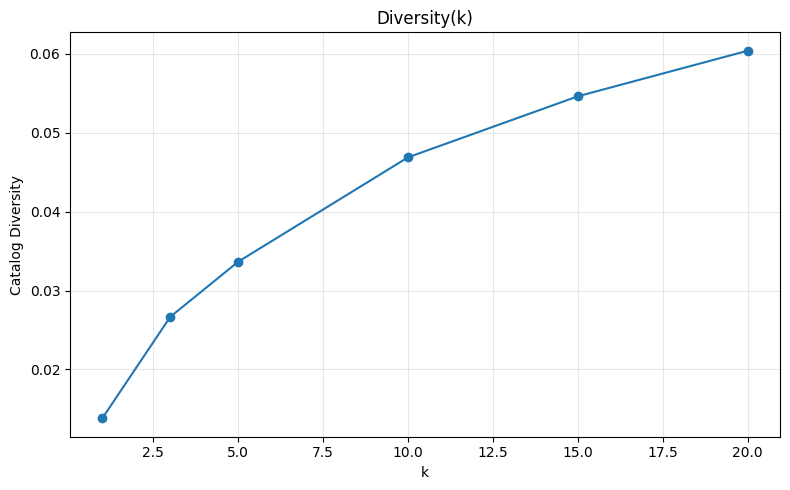

In [56]:
plt.figure(
    figsize=(8, 5)
)

plt.plot(
    diversity_df["k"],
    diversity_df["diversity"],
    marker="o"
)

plt.xlabel("k")
plt.ylabel("Catalog Diversity")
plt.title("Diversity(k)")

plt.grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()

«Diversity — какая доля каталога попадает хотя бы в одну выдачу топ-k. На
первом месте система показывает немного разных видео — тренды дня, а с
ростом k покрытие растёт, потому что ниже по списку работает
персонализация. Это ожидаемо для данных, где популярность — самый
сильный сигнал; повысить разнообразие можно переранжированием, но
ценой части точности»